<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U3/Practica_3/AD_U3_Pr%C3%A1ctica3_DelgadoRam%C3%ADrez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

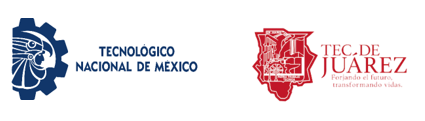

#**INSTITUTO TECNOLOGICO DE CIUDAD JUAREZ**
**Ciencia y analítica de datos**
*   NOMBRE: María Fernanda Delgado Ramírez
*   NO. CONTROL: 23111480

## **MODELOS DE APRENDIZAJE**
 **UNIDAD 3**

Serie de Tiempo

#### **En esta actividad trabajarás con datos históricos del precio de mercado de la acción de alguna de las grandes compañías como Nvidia, Tesla, Google.**

Sigue los siguientes pasos para descargar los datos del problema:

    Ir a la página de Yahoo!-Finance: https://finance.yahoo.com/

En el buscador de dicha página pon las iniciales de la compañía deseada. Deberás seleccionar alguna de las siguientes compañías: AAPL, NVDA, TSLA, GOOG, AMZN o MSFT.

Seleccionar la pestaña "Historical Data".

Pulsa "Download" para descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.



# **En esta Actividad se trabajará con los datos historicos del precio de mercado de la acción, Compañia MICROSOFT (MSFT).**

# **0 - Preparando los datos ORIGINALES**

In [ ]:
# Omitamos los Warnings por el momento:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
#!pip freeze   # Si deseas verificar qué librerías y versiones ya tiene google-Colab preinstaladas,
               # en particular "prophet" que usaremos en este ejercicio.

In [ ]:

#Libreria para obtener el conjunto de datos
import yfinance as yf

#Para manipular datos
import numpy as np
import pandas as pd

#Para graficar
import matplotlib.pyplot as plt

#Error cuadratico medio
from sklearn.metrics import mean_squared_error
import math

#Para aplicar escalamiento de datos [0,1]
from sklearn.preprocessing import MinMaxScaler

from prophet import Prophet
from statsmodels.graphics.tsaplots import month_plot, quarter_plot
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # gráficos de autocorrelación

#A) **Descargar el archivo de datos históricos de los movimientos diarios de los últimos 5 años.**

In [ ]:
#Escribimos las iniciales de la compañia con la que deseemos trabajar. En esta ocasión trabajare con Tesla

ticker_symbol = 'MSFT'                           # selecciona las iniciales de la compañía deseada.
data = yf.download(ticker_symbol, period='5y')   # Se indica el período de 5 años y descargamos.
data.to_csv('historical_data.csv')               # Guardamos los datos


[*********************100%***********************]  1 of 1 completed


In [ ]:
#convierte a dataframe
path = 'historical_data.csv'
df = pd.read_csv(path, header=2)   #header=2 para que no tome en cuenta los 2 primeros renglones, ya que estan vacios
df.columns=['Date','Adj Close','Close','High','Low','Open','Volume'] #Se agrega columna Date
df.head()

,Date,Adj Close,Close,High,Low,Volume
0,2021-11-05,322.525909,325.145975,320.951972,324.877253,22570100
1,2021-11-08,323.418518,324.051942,320.971225,323.716031,20897000
2,2021-11-09,322.420349,325.078783,321.057524,323.533607,21307400
3,2021-11-10,317.477844,321.153617,316.633309,321.096036,25500900
4,2021-11-11,319.042114,320.328145,317.199454,317.909643,16849800


In [ ]:
df.info()   # Verifica detalles del conjunto de datos a utilizar
            # El dataframe cuenta con 1258 registros
            # 7 columnas las cuales son: Date, Adj close, Close, High, Low, Open, Volume
            # Variable Date, tipo Object -> se cambiará a tipo Fecha

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       1254 non-null   object 
 1   Adj Close  1254 non-null   float64
 2   Close      1254 non-null   float64
 3   High       1254 non-null   float64
 4   Low        1254 non-null   float64
 5   Volume     1254 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 58.9+ KB


#**B)Utiliza solamente los datos de la columna "Adj Close" en esta actividad.**

In [ ]:
# Renombremos de manera estándar las columnas de fechas y valores de la
# serie de tiempo, donde además la fecha la trasnformamos a tipo datetime:

df = df.drop(columns=['Close','High','Low','Volume']) #Elimina columnas que no se requieren
df = df.rename(columns={'Adj Close':'y'})                    #Columna Adj Close, renombramos por y
df['Date'] = pd.to_datetime(df['Date'])                      #Convertimos variable Date de tipo Object a Datetime
df.head()                                                    #Muestra primeros 5 registros para visualizar el cambio

,Date,y
0,2021-11-05,322.525909
1,2021-11-08,323.418518
2,2021-11-09,322.420349
3,2021-11-10,317.477844
4,2021-11-11,319.042114


In [ ]:
df.info() #Creación de un nuevo df, el cual consta de 2 columnas, las cuales son:
          #Variable Date -> de tipo datetime64, nos ayuda a representar un rango de fechas muy amplio con presición nanosegundos
          #Variable 'Adj Close' -> fue renombrada por 'y' de tipo flotante,

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1254 entries, 0 to 1253
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1254 non-null   datetime64[ns]
 1   y       1254 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 19.7 KB


En particular datetime64[ns] nos ayuda a representar un rango de fechas muy amplio con precisión de nanosegundos.

### **Agreguemos los ajustes usuales en Series de tiempo:**

In [ ]:
# Hagamos una copia del DataFrame df con índices temporales:

df_temp = df.copy()                     #Genera copia del df originar en nueva variable temporal de nombre: df_temp
df_temp.set_index('Date', inplace=True) #se establece como indice Variable Date,
                                        #parametro inplace=True, es para guardar los cambios
df_temp.head()                          #visualizar los cambios

,y
Date,
2021-11-05,322.525909
2021-11-08,323.418518
2021-11-09,322.420349
2021-11-10,317.477844
2021-11-11,319.042114


In [ ]:
#Muestra información sobre numero total de registros y columnas como estan conformados el df original (df) y el df temporal (df_temp)

print("DataFrame Original:\n ")
print(df.shape)      #Conformado por 1258 registros y 2 columnas (Date, y)

print("\nDataFrame Temporal:\n")
print(df_temp.shape) #Conformado por 1258 regsitros y 1 columna (y), Variable Date pase a ser indice

DataFrame Original:
 
(1254, 2)

DataFrame Temporal:

(1254, 1)


https://pandas.pydata.org/docs/reference/api/pandas.DatetimeIndex.html

In [ ]:
# Ajustemos la frecuencia de los índices, para que el modelo tenga información del período en que
# se encuentran los datos:

df_temp.index =df_temp.index.tz_localize(None) #Para quitar zona horaria
df_temp.index


DatetimeIndex(['2021-11-05', '2021-11-08', '2021-11-09', '2021-11-10',
               '2021-11-11', '2021-11-12', '2021-11-15', '2021-11-16',
               '2021-11-17', '2021-11-18',
               ...
               '2026-10-22', '2026-10-23', '2026-10-26', '2026-10-27',
               '2026-10-28', '2026-10-29', '2026-10-30', '2026-11-02',
               '2026-11-03', '2026-11-04'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)

-----------------------------------------------------------------------------
**Se puede observar que la ejecución se esta línea de código indica 'freq=None', por lo cual tendremos que definir un tipo de frecuencia (ya sea por dias, meses, años). La cual se definirá en el siguiente segmento de código que se muestra a continuación:**

-----------------------------------------------------------------------------

Para las opciones de "freq" ver la tabla que viene en esta liga:

https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliases

In [ ]:
# Especifiquemos entonces que nuestros datos están registrados con una frecuencia mensual
# al inicio del mes (cada día 01 de cada mes):

df_temp = df_temp.resample('B').asfreq()#Define frecuencia B -> frecuencia del día de actividad
df_temp.index

DatetimeIndex(['2021-11-05', '2021-11-08', '2021-11-09', '2021-11-10',
               '2021-11-11', '2021-11-12', '2021-11-15', '2021-11-16',
               '2021-11-17', '2021-11-18',
               ...
               '2026-10-22', '2026-10-23', '2026-10-26', '2026-10-27',
               '2026-10-28', '2026-10-29', '2026-10-30', '2026-11-02',
               '2026-11-03', '2026-11-04'],
              dtype='datetime64[ns]', name='Date', length=1304, freq='B')

#**C)Investiga el significado de esta columna Adj-Close e inclúyelo en tu reporte del Jupyter-Notebook.**

###Investigación

-------------------------------------------------------------------------
¿Qué es el Cierre Ajustado?

Adj Close es una columna Clave dentro de los datos historicos . El **Precio Ajustado de cierre**, se apoya de dividendos y splist de acciones, que afectan el precio de la acción.

Es una versión ajustada del Precio de Cierre de una acción, después de los ajustes para todas las distribuciones de splits y dividendos aplicables, los cuales se definen a continuación:

 * **Dividendos**, Aqui es cuando la empresa distribuye dividendos a sus accionistas. El dividendo se "resta" del precio de la acción para representar el valor real de la acción después del pago realizado.

* **Splits(Divisiones de Acciones)**, Aqui es cuando el precio de la acción se ajusta para reflejar la nueva cantiad de acciones en circulación. Aumenta el número de acciones de circulación, pero la capitalización no cambia

##Importancia del Adj Close

El Adj Close, es muy importante ya que gracias a el se puede visualizar de mejor la manera la evolución del valor de la acción que se ha tenido a lo largo del tiempo. Siendo muy útil al momenteo de realizar análisis de rendimiento y asi lograr obtener una visipon más clara de cómo se ha comportado una acción dentro del mercado por un periodo de tiempo

De igual manera también es muy útil para realizar cálculos más precisos, si se desea cálcular el rendimiento total de una acción o retornos de una inversión en un cierto periodo, ya que por otro lado si se hace uso unicamente de "close" sin el ajuste, puede existir sesgo en el análisis.

--------------------------------------------------------------------

#**D)Divide los datos en Train y Test, donde Test serán los últimos 20 precios de mercado de la compañía que seleccionaste**

In [ ]:
df_temp=df_temp.ffill() #para rellenar datos faltantes NaN
datos_nan=df_temp[df_temp.isna().any(axis=1)] #para verificar existencia datos faltantes
#print(datos_nan)

In [ ]:
# Particionemos en entrenamiento y prueba como DataFrames de Pandas:
train = df_temp.iloc[0:-20,:] # Selecciona todos los registros, excepto últimos 20
test = df_temp.iloc[-20:,:]   # Seleccionamos los datos del últimoS 20 registros para predicción de Test.

In [ ]:
test.head()  #muestra registros del test

,y
Date,
2026-10-08,522.609985
2026-10-09,535.070007
2026-10-12,541.150024
2026-10-13,543.450012
2026-10-14,533.690002


In [ ]:
datos_nan=train[train.isna().any(axis=1)]
print(datos_nan) #verificamos que no existan datos faltantes NaN en Entrenamiento (train)

datos_nan=test[test.isna().any(axis=1)]
print(datos_nan) #verificamos que no exista datos faltantes NaN en Pueba (test)

Empty DataFrame
Columns: [y]
Index: []
Empty DataFrame
Columns: [y]
Index: []


In [ ]:
train.shape #Entrenamiento conformado por 1285 registros y 1 columna

(1284, 1)

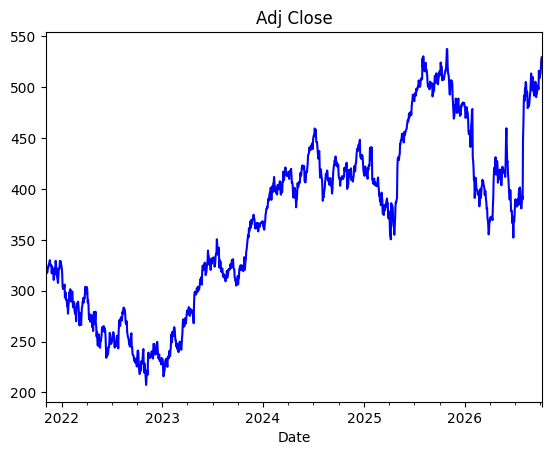

In [ ]:
# Gráfico con la periodicidad anual:
train['y'].plot(title='Adj Close', style='-b')
plt.show()

## <font color=orange>**Interpretación de la gráfica**</font>

La gráfica muestra cómo se movió el precio de cierre ajustado de la acción de Microsoft durante casi cinco años (de noviembre de 2021 a octubre de 2026), sin contar los últimos 20 días, que se dejaron aparte para la prueba. El precio no se mantiene estable: sube y baja constantemente, pero si se mira el conjunto completo se nota que la tendencia general es de crecimiento, ya que pasó de valores cercanos a los 320 dólares al inicio a valores cercanos a los 530 dólares al final.


## <font color=orange>**De este gráfico podemos observar:**

1.   **Una caída al inicio.** De finales de 2021 a finales de 2022 el precio bajó de forma continua, desde alrededor de 320 dólares hasta su punto más bajo, cerca de los 207 dólares.

2.   **Una recuperación larga.** A partir de 2023 el precio subió de manera sostenida hasta mediados de 2024, cuando llegó a cerca de 460 dólares. Esta es la etapa de crecimiento más estable de toda la serie.

3.   **Etapas de altibajos.** Después de esa subida, el precio se movió de lado y tuvo una caída en la primavera de 2025 (cerca de 350 dólares). Luego volvió a subir con fuerza hasta su máximo, de aproximadamente 537 dólares a finales de 2025, y de nuevo bajó a inicios y mediados de 2026.

4.   **Un salto repentino en 2026.** A mediados de 2026 el precio pasó de unos 390 dólares a cerca de 500 en muy poco tiempo, y desde entonces se mantiene en valores altos. Este tipo de cambios bruscos es difícil de anticipar para cualquier modelo.

5.   **No es una serie estable.** El precio no se queda alrededor de un mismo valor, sino que va cambiando de nivel con el tiempo (tiene tendencia). Además, el precio de un día es muy parecido al del día anterior, lo cual será importante para entender los resultados de los modelos más adelante.


# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ORIGINALES**

*   El modelo ingenuo simplemente **hace la predicción del siguiente período, repitiendo el valor del último período**.

*   Este modelo se utiliza en general como punto de partida **para comparar todos los demás**.

*   Utilicemos el error RMSE (Raíz del Error Cuadrático Medio) como medida del desempeño de nuestros modelos a obtener.

In [ ]:
test['y'].values #muestra valores del conjunto test en arreglo

array([522.60998535, 535.07000732, 541.15002441, 543.45001221,
       533.69000244, 539.44000244, 529.04998779, 533.52001953,
       531.86999512, 532.95001221, 521.08001709, 524.51000977,
       532.59997559, 531.33001709, 531.01000977, 530.14001465,
       521.90997314, 507.11999512, 520.98999023, 555.79998779])

In [ ]:
history = [x for x in train['y'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test['y'])):
  # Obtenemos las predicciones:
  yhat = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat)

  # Observaciones-registros reales:
  obs = test.iloc[i]['y']   # Ahora vamos tomando los datos de Test.
  history.append(obs)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-Naive: RMSE: %.3f' % rmse)

>Esperado-real = 522, Predicción = 529.760
>Esperado-real = 535, Predicción = 522.610
>Esperado-real = 541, Predicción = 535.070
>Esperado-real = 543, Predicción = 541.150
>Esperado-real = 533, Predicción = 543.450
>Esperado-real = 539, Predicción = 533.690
>Esperado-real = 529, Predicción = 539.440
>Esperado-real = 533, Predicción = 529.050
>Esperado-real = 531, Predicción = 533.520
>Esperado-real = 532, Predicción = 531.870
>Esperado-real = 521, Predicción = 532.950
>Esperado-real = 524, Predicción = 521.080
>Esperado-real = 532, Predicción = 524.510
>Esperado-real = 531, Predicción = 532.600
>Esperado-real = 531, Predicción = 531.330
>Esperado-real = 530, Predicción = 531.010
>Esperado-real = 521, Predicción = 530.140
>Esperado-real = 507, Predicción = 521.910
>Esperado-real = 520, Predicción = 507.120
>Esperado-real = 555, Predicción = 520.990

Error-Modelo-Naive: RMSE: 11.000


-----------------------------------------------------------------------------
## <font color=orange>**Interpretación**

El modelo ingenuo obtuvo un RMSE de **11.000**, lo que significa que en promedio sus predicciones se equivocaron por unos 11 dólares con respecto al precio real. Considerando que la acción ronda los 530 dólares, este error es pequeño (alrededor del 2 %).

Es un buen resultado para un modelo tan sencillo, y se explica porque el precio de un día suele ser muy parecido al del día anterior. Por esta razón, este valor se toma como punto de referencia: para que otro modelo se considere mejor, debe lograr un error menor a 11.

-----------------------------------------------------------------------------

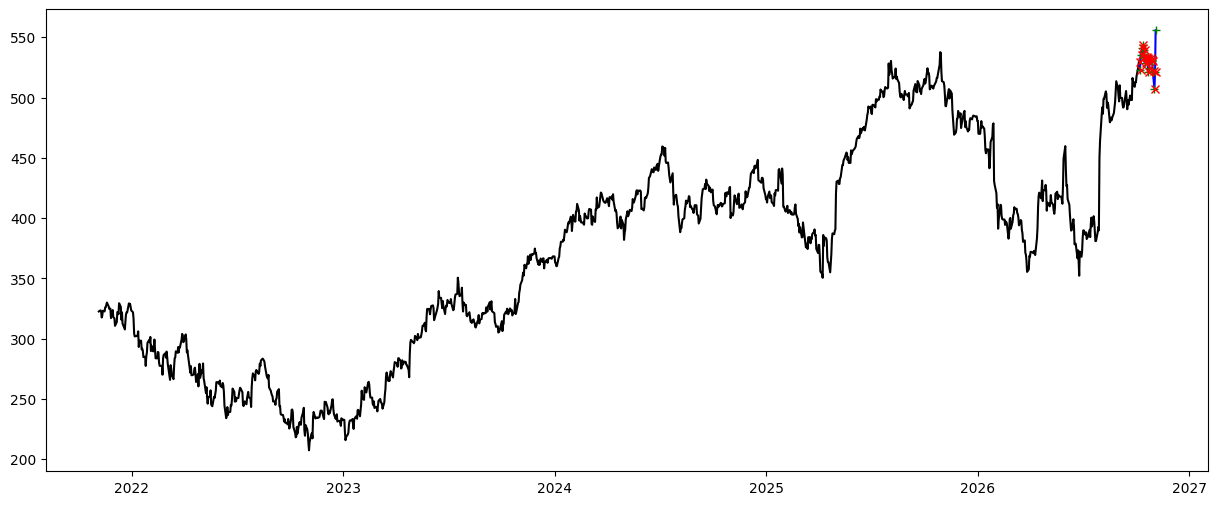

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')   # Datos de entrenamiento (los históricos).
ax = plt.plot(test['y'], '-b')    # Datos de prueba reales (los últimos 20 registros a predecir).
ax = plt.plot(test['y'],'+g')
ax = plt.plot(test.index, predictions, 'xr')  # Predicciones del modelo ingenuo.

#Verdes son los datos reales
#rojos son las predicciones

### <font color=orange>**Interpretación Gráfica.**

-----------------------------------------------------------------------------

En la gráfica, la línea negra son los datos históricos, la línea azul (con cruces verdes) son los precios reales de los últimos 20 días y las cruces rojas son las predicciones del modelo.

Se puede ver que las cruces rojas quedan muy cerca de los valores reales, pero siempre un paso atrás: como cada predicción es simplemente el precio del día anterior, el modelo no anticipa los cambios, solo los sigue con un día de retraso. Esto se nota más en el último día, donde el precio real subió a cerca de 556 dólares y el modelo predijo cerca de 521, que fue el error más grande de la prueba.

-----------------------------------------------------------------------------

# **2 - Modelo ARIMA**

# **DATOS ORIGINALES**

### **Análisis preliminar para obtener información de la serie de tiempo y construir el modelo ARIMA(p,d,q).**

*   **AR (AutoRegresivo):** El modelo se basa en la **relación entre un valor actual y sus valores pasados.**

*   **I (Integrado):** Se refiere a la diferenciación de la serie para hacerla estacionaria, es decir, eliminar tendencias y patrones cíclicos.

*   **MA (Media Móvil):** Usa el error de los valores pasados (las desviaciones entre valores predichos y observados) para corregir el valor actual.

##### **Ahora veamos el gráfico de descomposición de la serie de tiempo en sus componentes de tendencia (trend), estacionalidad (stationality) y residual (residual).**

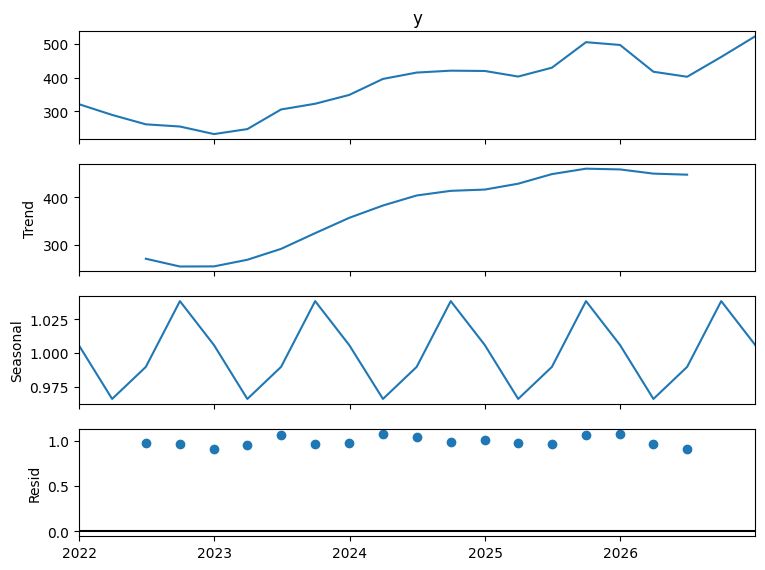

In [ ]:
# Gráficos de descomposición estacional:
#parametro Q indica año
decomposition = seasonal_decompose(train['y'].resample('Q').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

# <font color=orange>**Interpretación de cada una de las Gráficas**

-----------------------------------------------------------------------------

En esta gráfica nos desgloza 4 gráficas (los datos se agruparon por trimestres para esta descomposición):

1. **Gráfica Original**: muestra el precio promedio de cada trimestre. Se ve la caída de 2022 y la recuperación posterior, con un nivel alto al final del periodo.

2. **Tendencia (Trend)**: es la dirección general del precio sin los altibajos pequeños. Baja hasta 2022, sube de forma clara durante 2023 y 2024 (de unos 255 a unos 460 dólares) y después se mantiene casi estable.

3. **Estacional (Seasonal)**: es el patrón que se repite cada año. Aquí el patrón existe, pero es pequeño: hace que el precio varíe aproximadamente un 4 % hacia arriba o hacia abajo respecto a la tendencia, por lo que su efecto es débil comparado con la tendencia.

4. **Residuos (Resid)**: es lo que queda después de quitar la tendencia y el patrón anual. Los puntos se mantienen cerca de 1 y sin una forma definida, lo que indica que tendencia y estacionalidad explican buena parte del comportamiento y lo restante parece variación al azar.

-----------------------------------------------------------------------------

##### **Veamos ahora estos dos gráficos que nos hablan si tenemos algún tipo de estacionalidad (i.e., periodicidad). En particular, mensual o trimestral:**

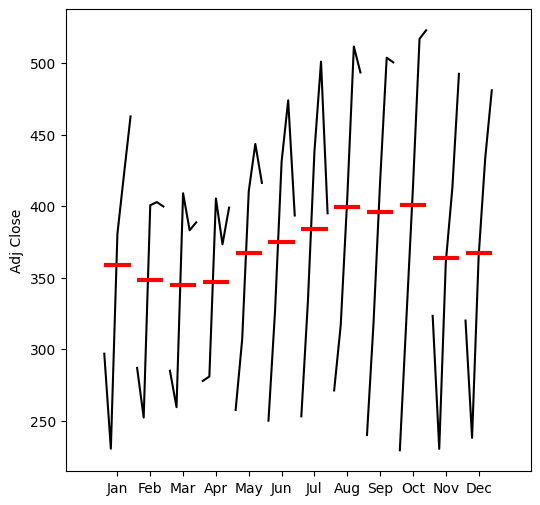

In [ ]:
# Gráfica para detección de estacionalidad mensual:
fig = month_plot(train['y'].resample('M').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------

En esta gráfica cada línea negra es un año y la línea roja es el promedio de cada mes. Los promedios son más altos de agosto a octubre (alrededor de 400 dólares) y más bajos de febrero a abril (alrededor de 345 dólares).

Sin embargo, no se ve una estacionalidad mensual clara: las líneas de cada año se comportan de forma distinta (en unos años el precio sube en un mes y en otros baja), y las diferencias entre los promedios se explican en buena parte por la tendencia de crecimiento de la serie y no por un patrón que se repita siempre en los mismos meses.

-----------------------------------------------------------------------------

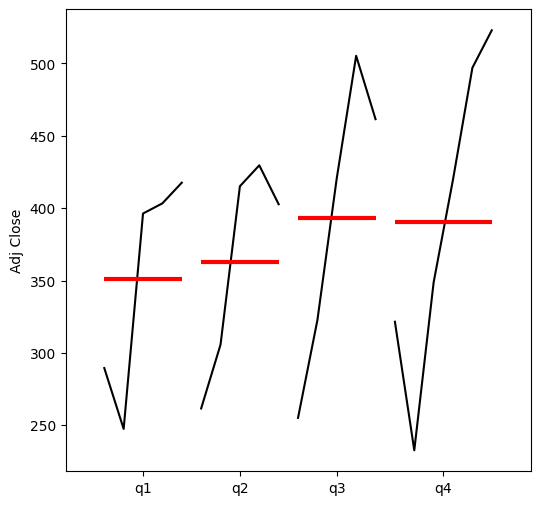

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral:
fig = quarter_plot(train['y'].resample('Q').mean(), ylabel='Adj Close')
fig.set_size_inches(6,6)
plt.show()

# <font color=orange>**Interpretación Gráfica**

-----------------------------------------------------------------------------

Al agrupar por trimestres, los promedios van de unos 351 dólares en el primer trimestre a unos 393 en el tercero, y el cuarto trimestre queda casi igual que el tercero. Es decir, parece haber un precio un poco más alto en la segunda mitad del año.

No obstante, las líneas de cada año siguen direcciones diferentes, por lo que el patrón no es lo bastante consistente para considerarlo una estacionalidad fuerte. Esto coincide con la descomposición anterior, donde el efecto estacional era pequeño.

-----------------------------------------------------------------------------

### **Gráficos de Autocorrelación (ACF) y Autocorrelación Parcial (PACF)**

*   Los gráficos de Autocorrelación miden la correlación entre la serie de tiempo y una versión rezagada de sí misma.

*   Este tipo de correlaciones de una serie de tiempo consigo misma son llamadas "autocorrelaciones" o "correlaciones seriales".

*   En el eje horizontal se muestra el valor del desfazamiento (lag) y en el eje vertical el valor de correlación de la serie desfazada y la original.

*   El cono sombreado indica intervalos de confianza de la correlación, con un 95% de confianza de manera predeterminada.

*   Que existan autocorrelaciones significativas en estos gráficos nos habla de que la serie de tiempo no es aleatoria.

*   En estos dos gráficos (llamados en inglés "pollipop plots") hay que determinar cuántos de estos lollipops están afuera del intervalo de confianza (sin contar el inicial) antes de que entre el siguiente a la zona celeste?

*   **Gráfico ACF:** Muestra la correlación total entre la serie y sus retardos, incluyendo efectos directos e indirectos.

*   **Gráfico PACF:** Muestra la correlación directa entre la serie y sus retardos, eliminando los efectos de los retardos intermedios.

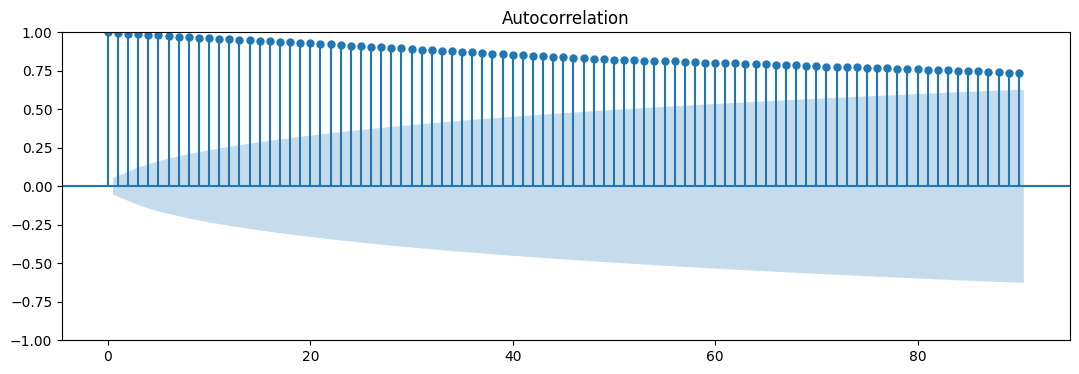

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function)
train['y'] = train['y'].ffill() ##Rellenan campos que estan NaN
fig,ax = plt.subplots(figsize = (13,4))
plot_acf(train['y'], lags=90, ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()

# <font color=orange>**Intepretación Gráfica Autocorrelación (ACF)**

-----------------------------------------------------------------------------

En esta gráfica todas las barras están muy por encima de la zona sombreada, incluso después de 90 desfases, y bajan muy lentamente (de 1 a cerca de 0.74). Esto quiere decir que el precio de hoy está fuertemente relacionado con los precios de los días anteriores, incluso con los de hace varios meses.

Este comportamiento es típico de una serie con tendencia, que no se mantiene alrededor de un mismo valor. Por eso, antes de aplicar ARIMA se trabaja con diferencias entre valores, para quitar la tendencia y que el modelo pueda aprender mejor.

-----------------------------------------------------------------------------

El gráfico inicia con desfase (lag) de 0, lo cual es la correlación de la serie de tiempo consigo misma, la cual es 1.

Posteriormente se muestran las correlaciones de la serie de tiempo original, con la serie desfasada "q" lugares hacia atrás, es decir, de orden "q" en la componente MA de ARIMA(p,d,q).

**El gráfico ACF nos dice en primera instancia que la componente MA de ARIMA(p,d,q) tiene un grado "q" de 13 (en la práctica se puede buscar de 0 a 13).**

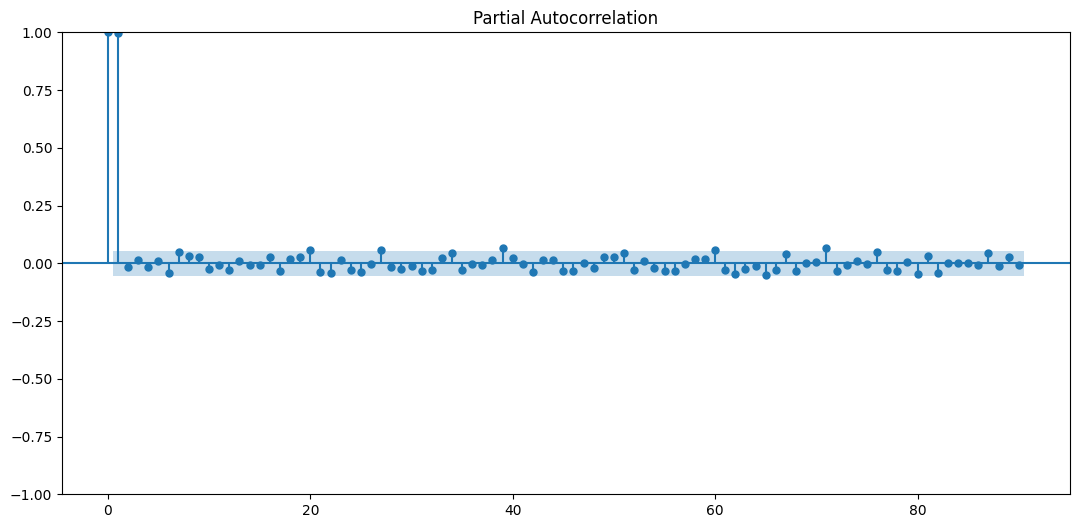

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF):
fig, ax = plt.subplots(figsize = (13,6))
plot_pacf(train['y'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

# <font color=orange>**Interpretación Gráfica Partial Autoccorelation (PACF)**

-----------------------------------------------------------------------------

En esta gráfica solo la primera barra (desfase 1) sobresale con claridad de la zona sombreada; las demás quedan dentro de ella o apenas la tocan. Esto significa que, una vez que se toma en cuenta el precio del día anterior, los precios de días más lejanos casi no aportan información nueva.

En otras palabras, el precio de hoy depende sobre todo del precio de ayer, lo cual coincide con lo observado en el modelo ingenuo y sugiere que el componente AR del modelo ARIMA puede ser pequeño (p = 1).

-----------------------------------------------------------------------------

* PACF también inicia con la correlación de la serie de tiempo consigo misma, por ello el valor de 1.

*   **De este gráfico podemos observar que la componente AR de ARIMA(p,d,q) tiene grado p=3 o tal vez 5 (en la práctica se puede probar de 0 a 5.)**

##### Existe un buen número de librerías para el caso de pronósticos con los modelos ARIMA-SARIMA. Usaremos en este ejercicio la de Statsmodels, cuya documentación encuentras en la siguiente liga:

https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
# Lo primero es para quitar la estacionalidad y transformar un problema
# de tipo no-estacionario (SARIMA) en uno estacionario (ARIMA):

# Diferencia de datos consecutivos en el tiempo
# y podemos ahora usar ARIMA:
def difference(dataset, interval=1):
  diff = list()

  for i in range(interval, len(dataset)):
    value = dataset[i] - dataset[i - interval]
    diff.append(value)

  return np.array(diff)



# Invierte las diferencias anteriores, es decir, nos regresa la estacionalidad:
def inverse_difference(history, yhat, interval=1):
  return yhat + history[-interval]


In [ ]:
# Definamos la siguiente lista de registros de pasajeros en el tiempo:
history = [x for x in train.loc[:,'y'].values]   # train-ndarray : columna solo con los registros de pasajeros "y".
                               # history-list : lista con los datos del train.

predictions = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test['y'])):
  #
  months_in_year = 12
  diff = difference(history, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.    (p,d,q)  p->valor definido en gráfica partial autocorrelation  d->Estacionaria  q->valor definido en grafica autocorrelacion
  model = ARIMA(diff, order=(1,0,13),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit = model.fit(method_kwargs={'maxiter':300})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat = model_fit.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat = inverse_difference(history, yhat, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions.append(yhat)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs = test.iloc[i]['y']   #  cada dato es un flotante.
  history.append(obs)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %3d, Predicción = %.3f' % (obs, yhat))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test['y'].values, predictions))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 522, Predicción = 528.291
>Esperado-real = 535, Predicción = 521.820
>Esperado-real = 541, Predicción = 536.482
>Esperado-real = 543, Predicción = 542.059
>Esperado-real = 533, Predicción = 542.279
>Esperado-real = 539, Predicción = 532.172
>Esperado-real = 529, Predicción = 540.973
>Esperado-real = 533, Predicción = 529.918
>Esperado-real = 531, Predicción = 533.521
>Esperado-real = 532, Predicción = 531.215
>Esperado-real = 521, Predicción = 534.975
>Esperado-real = 524, Predicción = 521.689
>Esperado-real = 532, Predicción = 523.267
>Esperado-real = 531, Predicción = 532.243
>Esperado-real = 531, Predicción = 532.306
>Esperado-real = 530, Predicción = 531.604
>Esperado-real = 521, Predicción = 529.047
>Esperado-real = 507, Predicción = 520.577
>Esperado-real = 520, Predicción = 508.103
>Esperado-real = 555, Predicción = 522.329

Error-Modelo-ARIMA: RMSE: 10.794


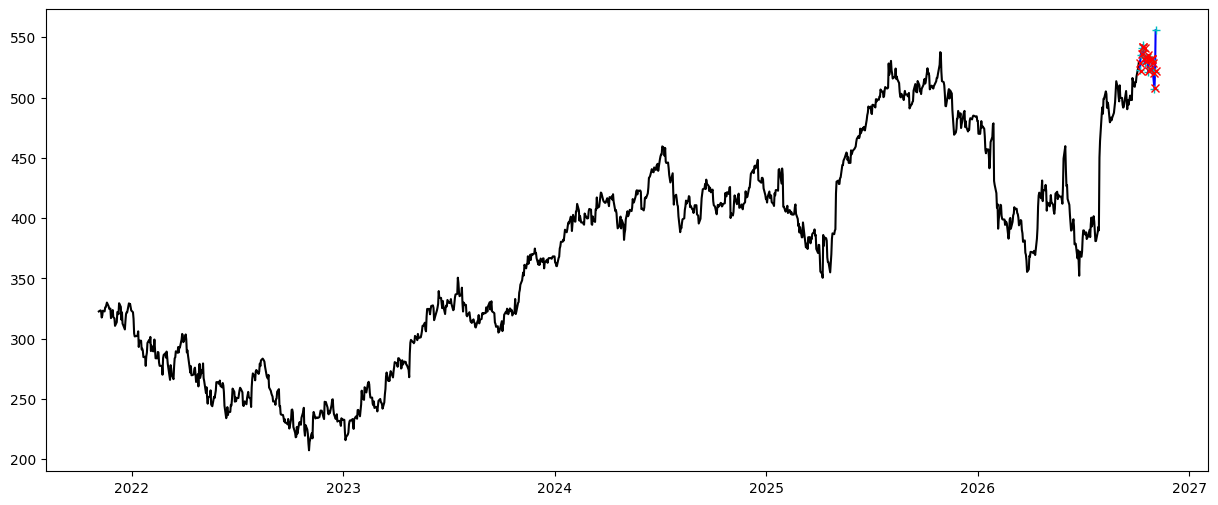

In [ ]:
# Veamos su gráfico de ARIMA:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train['y'], '-k')
ax = plt.plot(test['y'], '-b')
ax = plt.plot(test['y'], '+c')
ax = plt.plot(test.index, predictions, 'xr')

# <font color=orange>**Interpretación Gráfica ARIMA**

-----------------------------------------------------------------------------

El modelo ARIMA obtuvo un RMSE de **10.794**, es decir, se equivocó en promedio por unos 10.8 dólares. Es el mejor resultado de los cuatro modelos con los datos originales, aunque supera al modelo ingenuo (11.000) por muy poco, una diferencia de apenas unos 20 centavos de dólar.

En la gráfica, las cruces rojas (predicciones) acompañan de cerca los cambios del precio real, pero igual que en el modelo ingenuo, no lograron anticipar el salto del último día (cerca de 556 dólares). Esto confirma que ARIMA sigue bien el comportamiento diario, pero no puede prever cambios bruscos.

-----------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**

# **DATOS ORIGINALES**

#### **En la liga del modelo Facebook-Prophet puedes encontrar mucho más información, además de la documentación correspondiente:**

https://facebook.github.io/prophet/

In [ ]:
df_temp.head() #verificar que el df_temp este en formato correcto

,y
Date,
2021-11-05,322.525909
2021-11-08,323.418518
2021-11-09,322.420349
2021-11-10,317.477844
2021-11-11,319.042114


In [ ]:
# Prophet requiere que la entrada sean dos columnas, llamadas "ds" y "y".
# Les dmos esta forma usando el DataFrame "df" inicial:
df_temp = df_temp.reset_index() #reseta el indice
df_temp = df_temp.rename(columns={'Date': 'ds'}) #renombra columna 'Date' como 'ds'
df_temp.head()


,ds,y
0,2021-11-05,322.525909
1,2021-11-08,323.418518
2,2021-11-09,322.420349
3,2021-11-10,317.477844
4,2021-11-11,319.042114


In [ ]:
train =df_temp.iloc[0:-20,:] #particion Entrenamiento, todo el conjunto excepto últimos 20
test = df_temp.iloc[-20:,:]  #particion Prueba, solo ultimos 20 registros de df_temp

In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model = Prophet(seasonality_mode='multiplicative', #se especifica el modo multiplicativo que se definio en los modelos anteriores
                yearly_seasonality=True,       #periodo anual Verdadero
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30)    # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model.fit(train)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE:

pred_FP = model.predict(test)['yhat']
rmse = np.sqrt(mean_squared_error(test['y'], pred_FP))
print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet: RMSE: 14.278


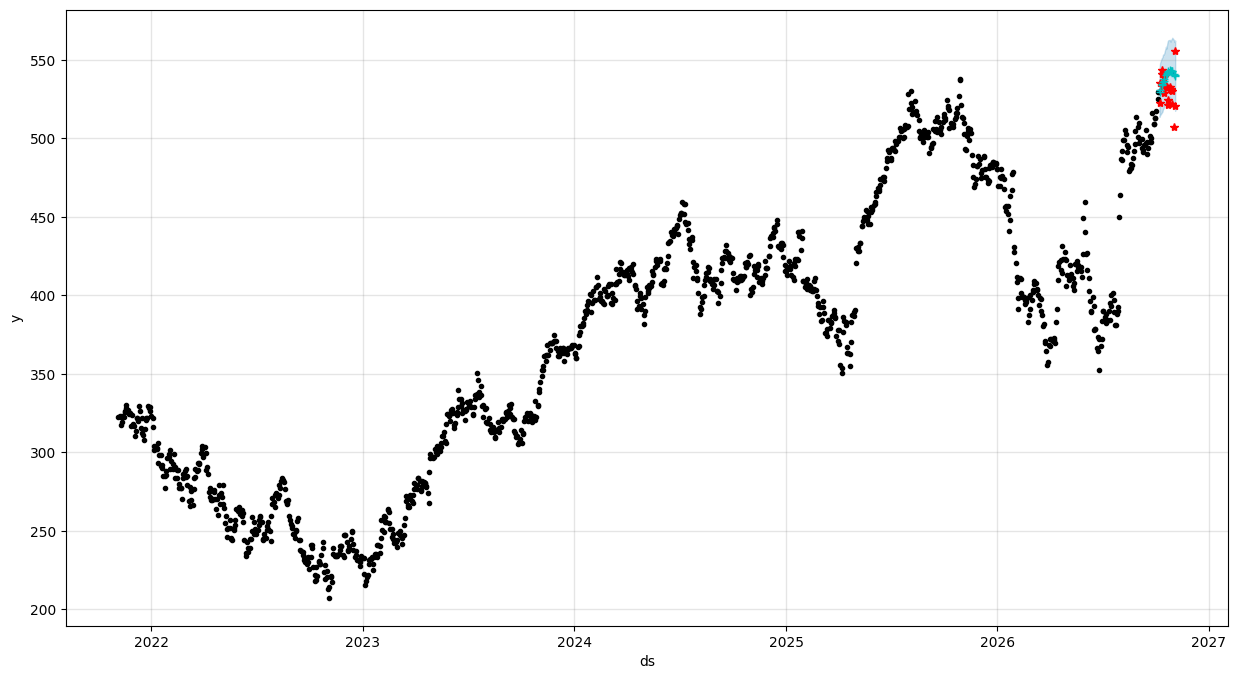

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast = model.predict(test)

fig, ax = plt.subplots(figsize=(15, 8))
model.plot(forecast, ax=ax)               # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test['ds'], test['y'], '*r')   # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test['ds'], forecast['yhat'], '+c')    # Valores reales.

#color rojo representan las predicciones
#color azul datos reales


# <font color=orange>**Interpretación Gráfica Facebook-Meta-Prophet**

-----------------------------------------------------------------------------

Puntos rojos -> datos reales de prueba (últimos 20 días)
Cruces azul claro -> predicciones del modelo
Parte sombreada -> intervalo de confianza (rango en el que el modelo espera que caiga el precio)

Prophet obtuvo un RMSE de **14.278**, por lo que se equivocó en promedio por unos 14 dólares, un error mayor que el del modelo ingenuo y el de ARIMA. En la gráfica se ve que su predicción es una curva suave que no reacciona a los cambios diarios y que queda un poco por encima de la mayoría de los valores reales, sobre todo en la segunda mitad de los 20 días. Aun así, casi todos los puntos reales caen dentro de la zona sombreada, lo que indica que el modelo marcó un rango razonable aunque no un valor preciso.

-----------------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ORIGINALES**

In [ ]:
import tensorflow as tf

In [ ]:
test.head()

,ds,y
1284,2026-10-08,522.609985
1285,2026-10-09,535.070007
1286,2026-10-12,541.150024
1287,2026-10-13,543.450012
1288,2026-10-14,533.690002


In [ ]:
def preparando_datos(myData, myDate):

  # ++++++++ TRAIN +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de entrenamiento son previos a la fecha "Date" que indiques y
  # tomarán hisotriales en este caso de 12 períodos previos.
  Train_Data = myData['y'][myData['ds'] < myDate].to_numpy()

  periodo = 12   # 12 meses al año

  Data_Train = []
  Data_Train_X = []
  Data_Train_Y = []

  for i in range(0, len(Train_Data), periodo):    # observa que va formando el Train set con historiales de 12 períodos consecutivos.
    try:
      Data_Train.append(Train_Data[i : i + periodo])
    except:
      pass


  # En ocasiones hay datos perdidos, en cuyo caso la última serie
  # de datos la eliminamos:
  if len(Data_Train[-1]) < periodo:
    Data_Train.pop(-1)


  # Hay que darle la forma (dimensionalidad) que requieren los modelos
  # de aprendizaje profundo, en particular la librería de TensorFlow:
  #     (batch_size, sequence_length, input_dimension).

  Data_Train_X = Data_Train[0 : -1]
  Data_Train_X = np.array(Data_Train_X)
  Data_Train_X = Data_Train_X.reshape((-1, periodo, 1))

  Data_Train_Y = Data_Train[1 : len(Data_Train)]
  Data_Train_Y = np.array(Data_Train_Y)
  Data_Train_Y = Data_Train_Y.reshape((-1, periodo, 1))


  # +++++++++++ TEST +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

  # Los datos de prueba (Test) son posteriores a la fecha "Date" y que es el
  # último ciclo que deseas predecir:
  Test_Data = myData['y'][myData['ds'] >= myDate].to_numpy()

  # inicialización de listas:
  Data_Test = []
  Data_Test_X = []
  Data_Test_Y = []

  for i in range(0, len(Test_Data), periodo):
    try:
      Data_Test.append(Test_Data[i : i + periodo])
    except:
      pass


  if len(Data_Test[-1]) < periodo:
    Data_Test.pop(-1)

  Data_Test_X = Data_Test[0 : -1]
  Data_Test_X = np.array(Data_Test_X)
  Data_Test_X = Data_Test_X.reshape((-1, periodo, 1))

  Data_Test_Y = Data_Test[1 : len(Data_Test)]
  Data_Test_Y = np.array(Data_Test_Y)
  Data_Test_Y = Data_Test_Y.reshape((-1, periodo, 1))


  return Data_Train_X, Data_Train_Y, Data_Test_X, Data_Test_Y


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date = '2024-09-11'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp, threshold_Date)#aplica df temporal

In [ ]:
# Podemos definir la manera en que el tamaño de paso (learning-rate) varíe
# en cada época. Es usual definir también algunas funciones, exponenciales,
# por ejemplo. Por el momento definamos valores constantes por intervalos:

def scheduler(epoch):

  if epoch <= 100:
    lrate = 0.05
  elif epoch <= 180:
    lrate = 0.0005
  elif epoch <=190:
    lrate = 0.00005
  else:
    lrate = (10 ** -5)

  return lrate


callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 14s 7s/step - loss: 102765.6406 - root_mean_squared_error: 320.5708 - val_loss: 184762.6250 - val_root_mean_squared_error: 429.8402 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - loss: 99003.2188 - root_mean_squared_error: 314.6478 - val_loss: 141393.0938 - val_root_mean_squared_error: 376.0227 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 87170.9766 - root_mean_squared_error: 295.2473 - val_loss: 94929.5781 - val_root_mean_squared_error: 308.1064 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - loss: 62733.6758 - root_mean_squared_error: 250.4669 - val_loss: 31724.2676 - val_root_mean_squared_error: 178.1131 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 27516.3926 - root_mean_squared_error: 165.8807 - val_loss: 21663.7285 - val_root_mean_squared_error: 147.1860 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0

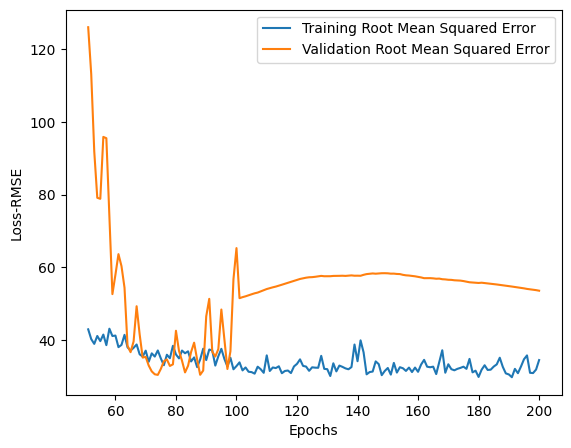

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(20, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.2),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model


# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
pred_LSTM=my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 515ms/step


(6480,)

In [ ]:
# Calculamos el error RMSE:

pred_LSTM = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM = pred_LSTM.reshape(-1)[-20:]  # Elegir los últimos 20 valores
rmse = np.sqrt(mean_squared_error(test['y'].values, pred_LSTM))

print('\nError-Modelo-FacebookProphet: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

Error-Modelo-FacebookProphet: RMSE: 74.123


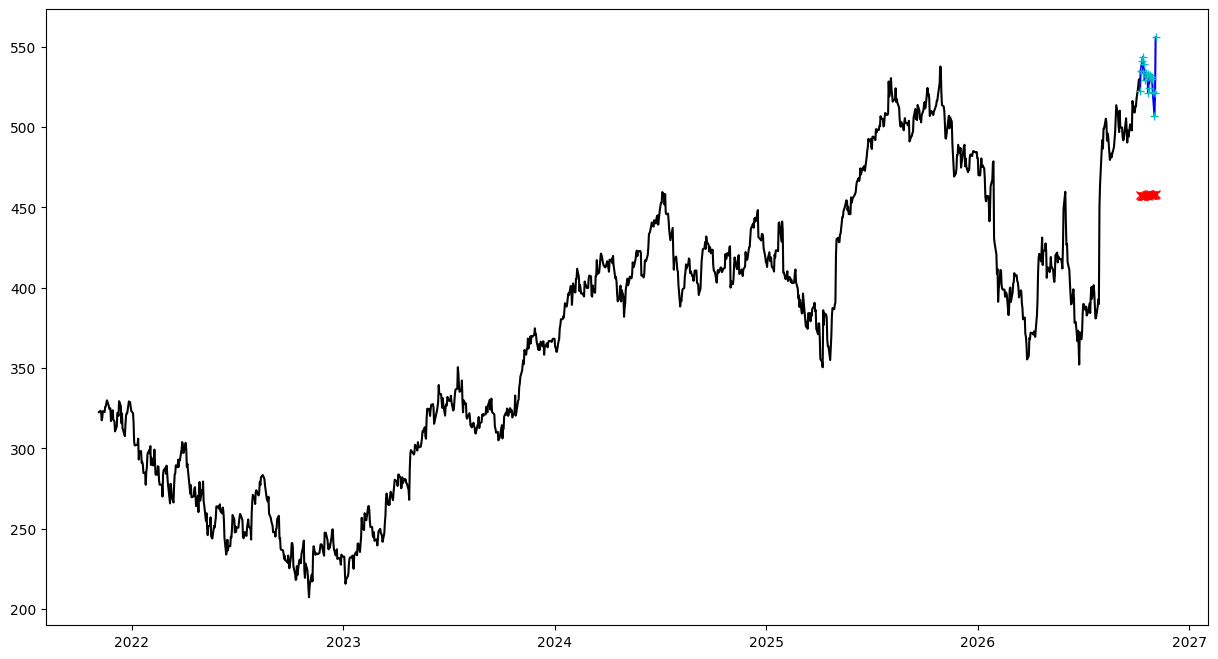

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(15, 8))
ax = plt.plot(train['ds'], train['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test['ds'], test['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], test['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test['ds'], pred_LSTM, 'xr')  # Predicciones del modelo del año 1960.

**Habría que buscar la mejor arquitectura y ejecutarlo varias veces para obtener un mejor resultado.**

# <font color=orange>**Interpretación Gráfica Long Short Term Memory (LSTM)**

-----------------------------------------------------------------------------

El modelo LSTM obtuvo un RMSE de **74.123**, el más alto de los cuatro. En la gráfica se observa que las cruces rojas forman una línea casi horizontal alrededor de los 457 dólares, mientras que el precio real estuvo entre 507 y 556 dólares. Es decir, el modelo predijo prácticamente el mismo valor para todos los días y se quedó unos 70 dólares por debajo.

Esto indica que, con esta configuración, la red no logró aprender bien el comportamiento reciente del precio, que estaba en niveles altos. Como se menciona arriba, habría que probar otras configuraciones y ejecutarlo varias veces para mejorar el resultado.

-----------------------------------------------------------------------------

# <font color=orange>**Interpretación Valores RMSE Obtenidos de los modelos Ingenuo, ARIMA, Prophet y LSTM aplicado con Datos Orginales**</font>

-----------------------------------------------------------------------------

Los resultados obtenidos de RMSE, fueron los siguientes:

| # | Modelo  | Datos Originales RMSE |
|---|---------|-----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 11.000 |
| 2 | Modelo ARIMA | 10.794 |
| 3 | Modelo Facebook-Meta-Prophet | 14.278 |
| 4 | Long Short Term Memory (LSTM) | 74.123 |

**<font color=orange>INTERPRETACIÓN Y CONCLUSIÓN DE LA PRÁCTICA: </FONT>**

---------------------------------------------------------------------------

Con los datos originales, el mejor resultado fue el del modelo ARIMA (10.794), seguido muy de cerca por el modelo ingenuo (11.000). La diferencia entre ambos es tan pequeña que en la práctica se pueden considerar equivalentes. Prophet quedó en tercer lugar (14.278) y el LSTM fue el que más se alejó (74.123), con un error cerca de siete veces mayor que el del modelo ingenuo.

Un resultado importante es que los modelos más complejos no superaron claramente al más sencillo. Esto se debe a que el precio de la acción cambia poco de un día a otro, por lo que repetir el valor de ayer ya es una predicción bastante buena. Además, el modelo ingenuo y ARIMA se van actualizando cada día con el precio real, mientras que Prophet y LSTM predicen los 20 días de una sola vez a partir de lo aprendido en el entrenamiento, lo que los pone en desventaja.

En conclusión, para predecir el precio de Microsoft en un plazo corto de 20 días, ARIMA y el modelo ingenuo ofrecieron los errores más bajos (cerca de 11 dólares, alrededor del 2 % del precio), y ninguno de los modelos pudo anticipar el salto del último día.

---------------------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **A continuación, se aplicaran los mismos modelos planteados anteriormente (Ingenuo, ARIMA, Prophet y LSTM), pero aplicando escalamiento MinMaxScaler al conjunto de datos que estamos trabajando (ADJ-CLOSE).**

# **0 -PREPARACIÓN DATOS PARA ESCALAMIENTO**

# **DATOS ESCALADOS**

In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))#aplica escalamiento rango 0,1

#Aplica Escalamiento a Entrenamiento y Prueba
train.loc[:, 'y_escalado'] = scaler.fit_transform(train[['y']])
test.loc[:, 'y_escalado']=scaler.transform(test[['y']])

In [ ]:
train.head() #para visualizar nueva columna con los valores 'y' escalados

,ds,y,y_escalado
0,2021-11-05,322.525909,0.348717
1,2021-11-08,323.418518,0.351420
2,2021-11-09,322.420349,0.348398
3,2021-11-10,317.477844,0.333434
4,2021-11-11,319.042114,0.338170


In [ ]:
#Elimina columna 'y' para quedarnos solo con las columnas: 'ds'  'y_escalado'
train_escalado=train.drop(columns=['y'])
test_escalado=test.drop(columns=['y'])

In [ ]:
train_escalado.head()#verifica eliminacion columna 'y'

,ds,y_escalado
0,2021-11-05,0.348717
1,2021-11-08,0.351420
2,2021-11-09,0.348398
3,2021-11-10,0.333434
4,2021-11-11,0.338170


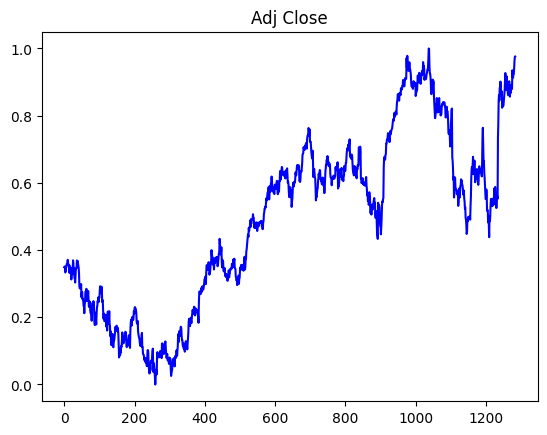

In [ ]:
train_escalado['y_escalado'].plot(title='Adj Close', style='-b')
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo Obtenido en Datos Originales**

-----------------------------------------------------------------------------

La forma de la gráfica es exactamente la misma que con los datos originales: la misma caída de 2022, la misma recuperación y los mismos altibajos posteriores. Lo único que cambia es la escala del eje vertical, que ahora va de 0 a 1, donde 0 corresponde al precio más bajo del entrenamiento (cerca de 207 dólares) y 1 al más alto (cerca de 538 dólares).

Esto demuestra que escalar los datos no modifica el comportamiento de la serie, solo cambia las unidades en que se expresa.

-----------------------------------------------------------------------------

In [ ]:
test_escalado['y_escalado'].values   #muestra valores del test con los datos escalados

array([0.95447698, 0.99220002, 1.01060743, 1.0175707 , 0.98802202,
       1.00543029, 0.97397425, 0.98750739, 0.9825119 , 0.98578168,
       0.94984496, 0.96022935, 0.98472193, 0.9808771 , 0.97990827,
       0.97727434, 0.95235767, 0.90758063, 0.9495724 , 1.05496057])

# **1 - Modelo ingenuo (Baseline / Persistance / Naive model)**

# **DATOS ESCALADOS**

In [ ]:
history = [x for x in train_escalado['y_escalado'].values]   # Definimos "history" donde de manera incremental se irán agregando registros mensuales.
predictions = list()    # Lista que contendrá las predicciones del modelo ingenuo.

for i in range(len(test_escalado['y_escalado'])):
  # Obtenemos las predicciones:
  yhat_scaled = history[-1]   # La primera vez, tomamos el último dato del Train, en las siguientes, se van agregando los datos de Test.
  predictions.append(yhat_scaled)

  # Observaciones-registros reales:
  obs_scaled = test_escalado.iloc[i]['y_escalado']   # Ahora vamos tomando los datos de Test.
  history.append(obs_scaled)  # Vamos agregando a "history" (que ya tiene todo los de Train) en cada iteración, un dato más de los de Test.
  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_scaled, yhat_scaled))


# Calculamos la raíz del error cuadrático medio (RMSE):
rmse = np.sqrt(mean_squared_error(test_escalado['y_escalado'].values, predictions))
print('\nError-Modelo-Naive con datos escalados: RMSE: %.3f' % rmse)

>Esperado-real = 0.954, Predicción = 0.976
>Esperado-real = 0.992, Predicción = 0.954
>Esperado-real = 1.011, Predicción = 0.992
>Esperado-real = 1.018, Predicción = 1.011
>Esperado-real = 0.988, Predicción = 1.018
>Esperado-real = 1.005, Predicción = 0.988
>Esperado-real = 0.974, Predicción = 1.005
>Esperado-real = 0.988, Predicción = 0.974
>Esperado-real = 0.983, Predicción = 0.988
>Esperado-real = 0.986, Predicción = 0.983
>Esperado-real = 0.950, Predicción = 0.986
>Esperado-real = 0.960, Predicción = 0.950
>Esperado-real = 0.985, Predicción = 0.960
>Esperado-real = 0.981, Predicción = 0.985
>Esperado-real = 0.980, Predicción = 0.981
>Esperado-real = 0.977, Predicción = 0.980
>Esperado-real = 0.952, Predicción = 0.977
>Esperado-real = 0.908, Predicción = 0.952
>Esperado-real = 0.950, Predicción = 0.908
>Esperado-real = 1.055, Predicción = 0.950

Error-Modelo-Naive con datos escalados: RMSE: 0.033


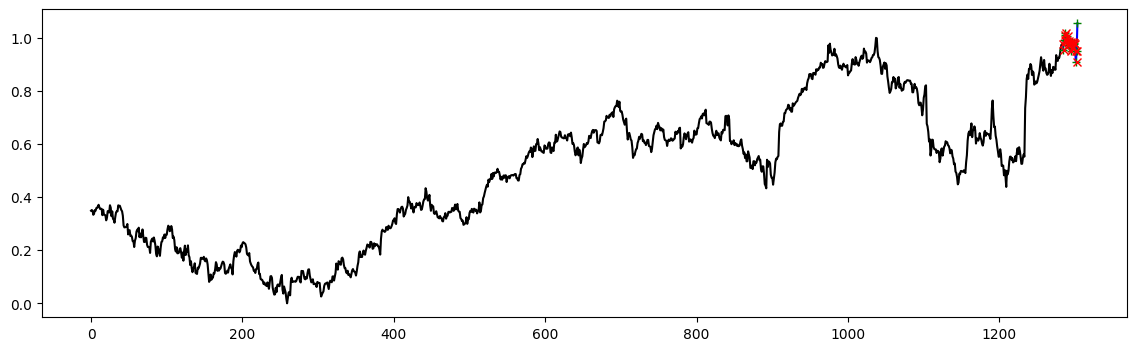

In [ ]:
# Grafiquemos los resultados:

fig, ax = plt.subplots(figsize=(14, 4))
ax = plt.plot(train_escalado['y_escalado'], '-k')  # Datos de entrenamiento (los históricos).
ax = plt.plot(test_escalado['y_escalado'], '-b')    # Datos de prueba reales (los del útimo año a predecir).
ax = plt.plot(test_escalado['y_escalado'],'+g')
ax = plt.plot(test_escalado.index, predictions, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en el modelo ingenuo con los datos originales**

-----------------------------------------------------------------------------

La gráfica es igual a la del modelo ingenuo con datos originales: las predicciones siguen a los valores reales con un día de retraso. El RMSE fue de **0.033**, que equivale aproximadamente a los 11 dólares obtenidos antes (el rango de precios del entrenamiento es de unos 330 dólares, y 0.033 por 330 da cerca de 11).

Como el modelo solo repite el valor anterior, escalar los datos no cambia su resultado, solo cambia la forma en que se expresa el error.

-----------------------------------------------------------------------------

# **2 - Modelo ARIMA**
# **DATOS ESCALADOS**

In [ ]:
#copia df con Conjunto Entrenamiento
train_escalado2=train_escalado.copy()
train_escalado2.head()

,ds,y_escalado
0,2021-11-05,0.348717
1,2021-11-08,0.351420
2,2021-11-09,0.348398
3,2021-11-10,0.333434
4,2021-11-11,0.338170


In [ ]:
#copia df Conjunto de Prueba
test_escalado2=test_escalado.copy()
test_escalado2.head()

,ds,y_escalado
1284,2026-10-08,0.954477
1285,2026-10-09,0.992200
1286,2026-10-12,1.010607
1287,2026-10-13,1.017571
1288,2026-10-14,0.988022


In [ ]:
train_escalado2 = train_escalado2.set_index('ds') #Aplica ds como índice en conjunto entrenamiento

In [ ]:
test_escalado2 =test_escalado2.set_index('ds')   #Aplica ds como índice en conjunto de Prueba

In [ ]:
train_escalado2.head()  #Verifica datos escalados Entrenamiento

,y_escalado
ds,
2021-11-05,0.348717
2021-11-08,0.351420
2021-11-09,0.348398
2021-11-10,0.333434
2021-11-11,0.338170


In [ ]:
test_escalado2.head() #Verificar datos Escalados Prueba

,y_escalado
ds,
2026-10-08,0.954477
2026-10-09,0.992200
2026-10-12,1.010607
2026-10-13,1.017571
2026-10-14,0.988022


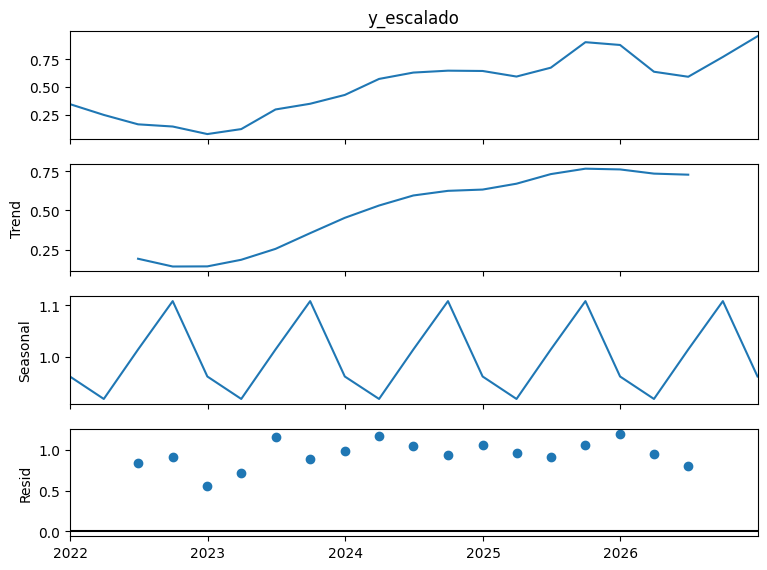

In [ ]:
# Gráficos de descomposición estacional con datos escalados:
decomposition = seasonal_decompose(train_escalado2['y_escalado'].resample('QE').mean(), model='multiplicative')  # <<<---- Observa que el modelo es multiplicativo
fig = decomposition.plot()
fig.set_size_inches(8,6)
plt.show()

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con Datos Originales**

-----------------------------------------------------------------------------

La tendencia y el patrón estacional tienen la misma forma que con los datos originales: la tendencia baja hasta 2022, sube hasta 2024 y luego se estabiliza, y el patrón anual se repite en las mismas épocas del año.

La diferencia es que aquí el patrón estacional parece más grande (varía entre 0.9 y 1.1, contra 0.96 y 1.04 en los datos originales) y los residuos están más dispersos. Esto no significa que la acción se comporte distinto, sino que el modelo multiplicativo se ve afectado cuando los valores escalados están muy cerca de cero.

-----------------------------------------------------------------------------

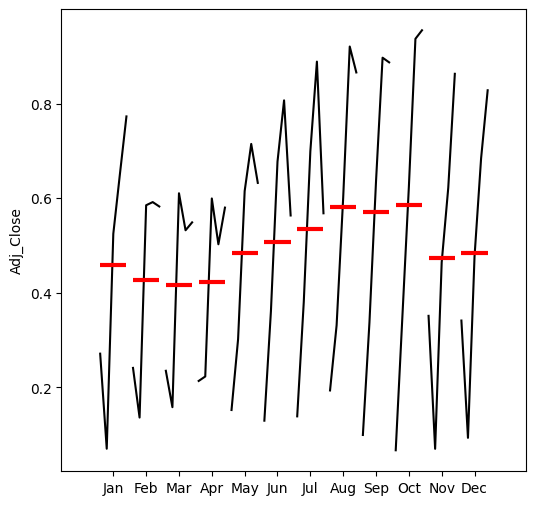

In [ ]:
# Gráfica para detección de estacionalidad mensual con datos escalados:
fig = month_plot(train_escalado2['y_escalado'].resample('M').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

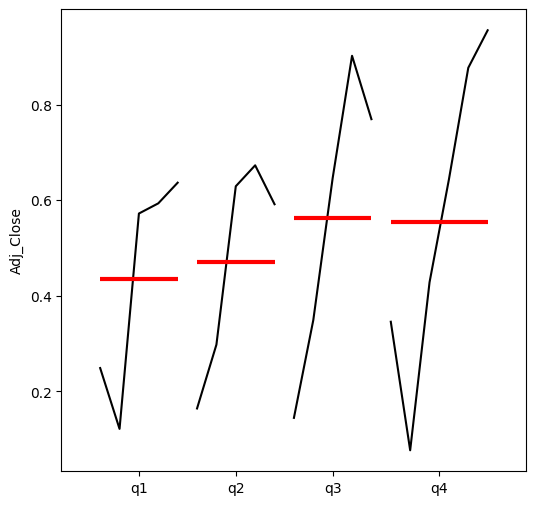

In [ ]:
# Si queremos graficar y detectar estacionalidad trimestral con datos escalados:
fig = quarter_plot(train_escalado2['y_escalado'].resample('Q').mean(), ylabel='Adj_Close')
fig.set_size_inches(6,6)
plt.show()

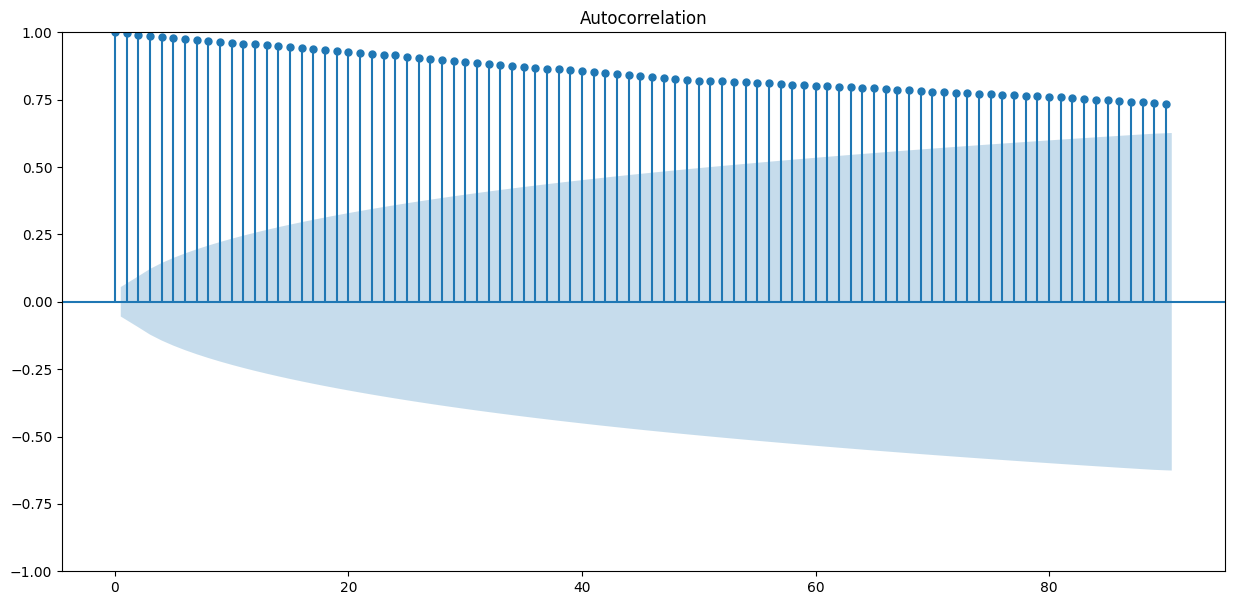

In [ ]:
# Gráfico de Autocorrelación (ACF: Auto-Correlation-Function) con datos escalados
fig,ax = plt.subplots(figsize = (15,7))
plot_acf(train_escalado2['y_escalado'], lags = 90,ax=ax)   # Eliges el número de unidades (meses) desfasadas. El número de "lags" es el número
plt.show()                          # que define la partición en el eje horizontal. El área no sombreada nos habla de
                                    # la cantidad de períodos de tiempo hacia atrás cuya información proporcionada es
                                    # significativa para la predicción futura.


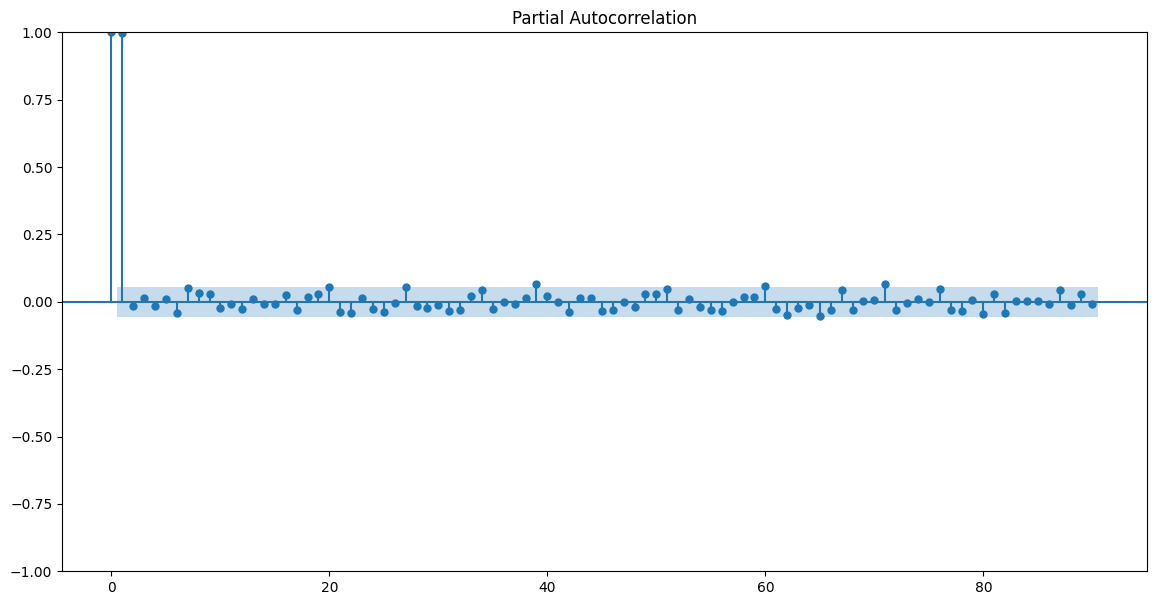

In [ ]:
# Gráfico de Autocorrelación Parcial (PACF) con datos escalados:
fig, ax = plt.subplots(figsize = (14,7))
plot_pacf(train_escalado2['y_escalado'], lags = 90, ax = ax, method="ols")   # ols: regression of time series on lags of it an on constant. predetrminado method="ywm"
plt.show()

In [ ]:
# Definamos la siguiente lista de registros de Adj Close en el tiempo con datos escalados:
history_escalado = [x for x in train_escalado2.loc[:,'y_escalado'].values]   # train-ndarray : columna solo con los registros de Adj Close "y".
                               # history-list : lista con los datos del train.

predictions_escalado = list()   # Para incluir las predicciones que vaya generando el modelo.

for i in range(len(test_escalado2['y_escalado'])):
  #
  months_in_year = 12
  diff = difference(history_escalado, months_in_year)    # diff-list: lista de los datos de diferencias para transformar SARIMA en ARIMA.

  # Generamos el modelo.
  model_escalado = ARIMA(diff, order=(1,0,5),) # Si aplicamos diff, entonces d=0 es aplicable.
  model_fit_escalado = model_escalado.fit(method_kwargs={'maxiter':500})  # Aumentar las iteraciones para evitar el WarningConvergence.

  yhat_escalado = model_fit_escalado.forecast()[0]   # prediccions (yhat) de cada registro, es un solo número flotante.
  yhat_escalado = inverse_difference(history_escalado, yhat_escalado, months_in_year)    # El "history" sigue siendo la lista de arriba.
                                                              # El nuevo "yhat" es cada un nuevo valor (float) de predicción.
  predictions_escalado.append(yhat_escalado)  # predictions-list : lista que se va incrementando al ir agregando cada predicción nueva.

  # Observaciones-reales:
  obs_escalado = test_escalado2.iloc[i]['y_escalado']   #  cada dato es un flotante.
  history_escalado.append(obs_escalado)   #  history-list : se va incrementado a partir del Train con los registros-observaciones reales.

  print('>Esperado-real = %.3f, Predicción = %.3f' % (obs_escalado, yhat_escalado))

# Error RMSE:
rmse = np.sqrt(mean_squared_error(test_escalado2['y_escalado'].values, predictions_escalado))
print('\nError-Modelo-ARIMA: RMSE: %.3f' % rmse)

>Esperado-real = 0.954, Predicción = 0.959
>Esperado-real = 0.992, Predicción = 0.959
>Esperado-real = 1.011, Predicción = 0.975
>Esperado-real = 1.018, Predicción = 1.056


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


>Esperado-real = 0.988, Predicción = 0.986
>Esperado-real = 1.005, Predicción = 0.981
>Esperado-real = 0.974, Predicción = 1.009
>Esperado-real = 0.988, Predicción = 0.969
>Esperado-real = 0.983, Predicción = 0.993
>Esperado-real = 0.986, Predicción = 0.998
>Esperado-real = 0.950, Predicción = 0.998
>Esperado-real = 0.960, Predicción = 0.947
>Esperado-real = 0.985, Predicción = 0.942
>Esperado-real = 0.981, Predicción = 1.018
>Esperado-real = 0.980, Predicción = 0.998
>Esperado-real = 0.977, Predicción = 0.988
>Esperado-real = 0.952, Predicción = 0.952
>Esperado-real = 0.908, Predicción = 0.977
>Esperado-real = 0.950, Predicción = 0.879
>Esperado-real = 1.055, Predicción = 0.969

Error-Modelo-ARIMA: RMSE: 0.039


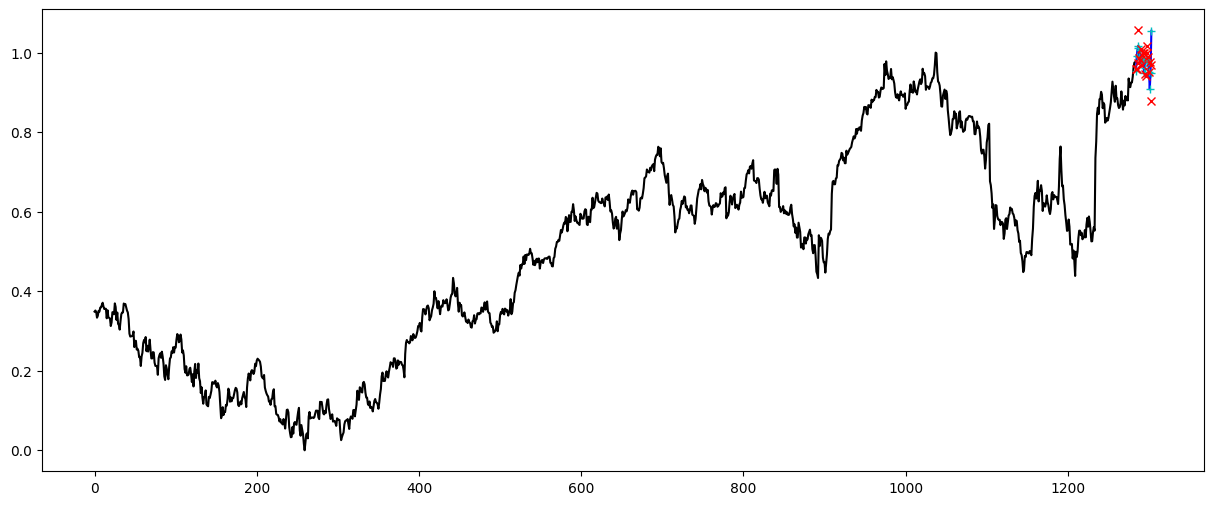

In [ ]:
# Veamos su gráfico:
fig, ax = plt.subplots(figsize=(15, 6))
ax = plt.plot(train_escalado['y_escalado'], '-k')
ax = plt.plot(test_escalado['y_escalado'], '-b')
ax = plt.plot(test_escalado['y_escalado'], '+c')
ax = plt.plot(test_escalado.index, predictions_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica Modelo ARIMA, Comparativa con datos originales**

-----------------------------------------------------------------------------

La gráfica es muy parecida a la de los datos originales: las predicciones siguen de cerca al precio real, aunque no anticipan el salto del último día. El RMSE fue de **0.039**, equivalente a unos 13 dólares, algo mayor que el del modelo ingenuo escalado (0.033).

En los datos originales ARIMA había quedado ligeramente mejor que el ingenuo, y aquí quedó ligeramente peor. Esto no se debe solo al escalamiento: en esta versión se usó una configuración un poco distinta (menos términos de media móvil) y, además, en una de las ejecuciones el modelo mostró una advertencia de que no terminó de ajustarse por completo.

-----------------------------------------------------------------------------

# **3 - Modelo Facebook-Meta-Prophet**
# **DATOS ESCALADOS**

In [ ]:
df_temp_escalado=df_temp.copy() #copia en nuevo df
df_temp_escalado.head()

,ds,y
0,2021-11-05,322.525909
1,2021-11-08,323.418518
2,2021-11-09,322.420349
3,2021-11-10,317.477844
4,2021-11-11,319.042114


In [ ]:
df_temp_escalado= df_temp_escalado.rename(columns={'Date':'ds','y_escalado':'y'})
df_temp_escalado.head()

,ds,y
0,2021-11-05,322.525909
1,2021-11-08,323.418518
2,2021-11-09,322.420349
3,2021-11-10,317.477844
4,2021-11-11,319.042114


In [ ]:
train_escalado = df_temp_escalado.iloc[0:-20,:] #partición Entrenamiento. Todos menos los últimos 20 registros
test_escalado = df_temp_escalado.iloc[-20:,:] #partición Prueba. Solo los últimos 20 registros

In [ ]:
#Aplica Escalamiento MinMaxScaler a entrenamiento y prueba
scaler = MinMaxScaler(feature_range=(0, 1))
train_escalado.loc[:, 'y']=scaler.fit_transform(train_escalado[['y']])
test_escalado.loc[:, 'y']=scaler.transform(test_escalado[['y']])

In [ ]:
train_escalado.head()

,ds,y
0,2021-11-05,0.348717
1,2021-11-08,0.351420
2,2021-11-09,0.348398
3,2021-11-10,0.333434
4,2021-11-11,0.338170


In [ ]:
# Aplicamos el modelo Facebbok-Prophet a nuestros datos:

model_escalado = Prophet(seasonality_mode='multiplicative',
                yearly_seasonality=True,
                changepoint_prior_scale=10.,   # Controla la flexibilidad de la componente Trend, mayor valor mayores fluctuaciones.
                seasonality_prior_scale=30,)   # Controla la estacionalidad, mayor el valor, mayor flexibilidad en la estacionalidad.
model_escalado.fit(train_escalado)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [ ]:
# Calculamos el error RMSE con datos escalados:
pred_FP_escalado = model_escalado.predict(test_escalado)['yhat']
rmse = np.sqrt(mean_squared_error(test_escalado['y'], pred_FP_escalado))
print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)


Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.047


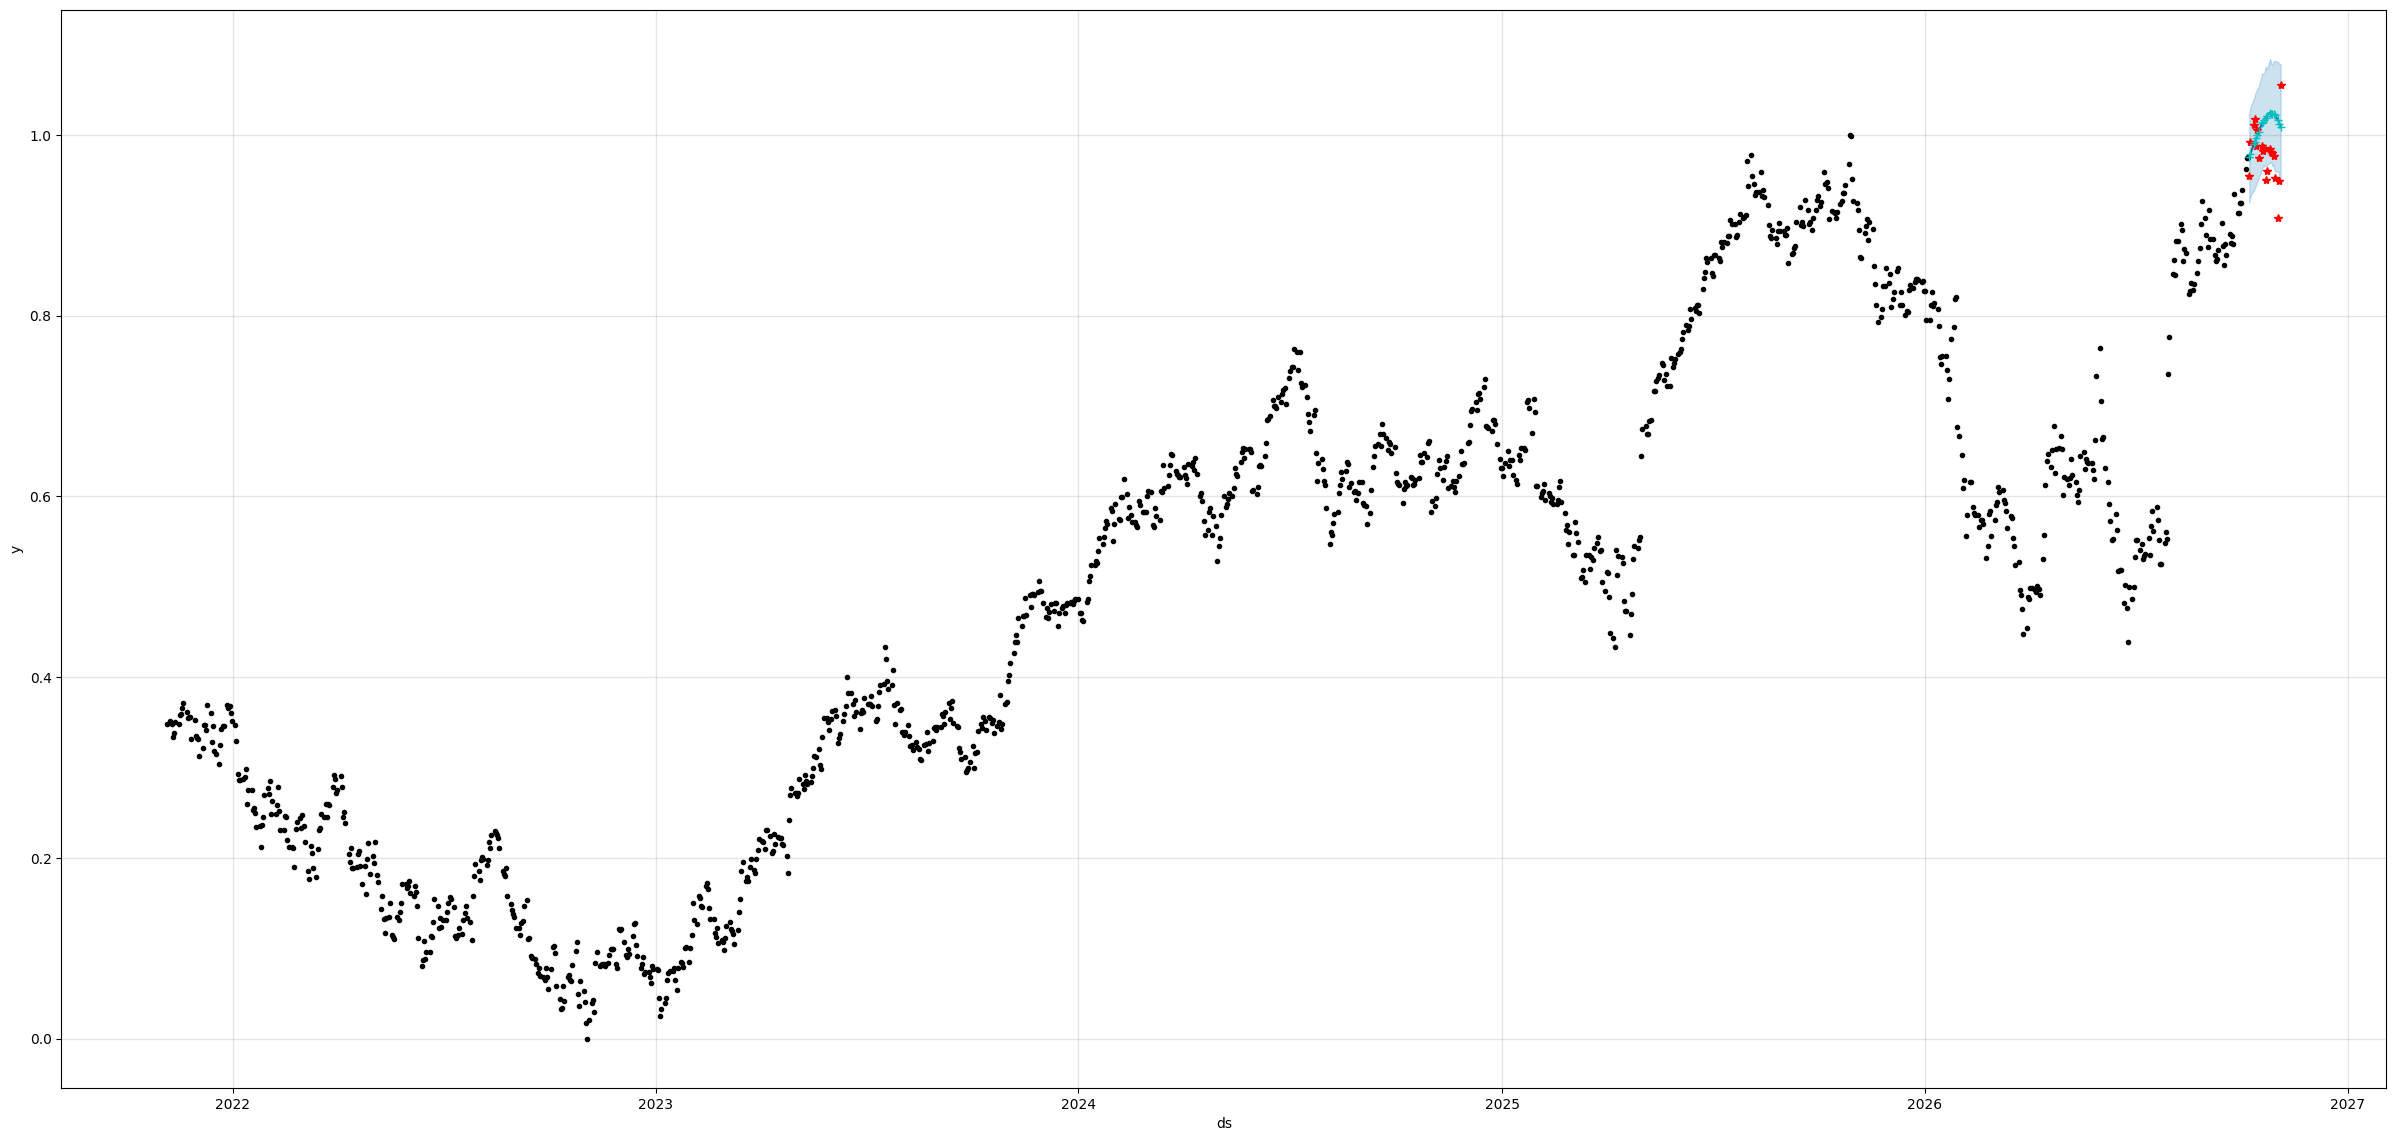

In [ ]:
# La librería misma nos permite obtener las predicciones con las cotas mínima
# y máxima, además de su gráfica, como se muestra a continuación:

forecast_escalado = model_escalado.predict(test_escalado)

fig, ax = plt.subplots(figsize=(30, 14))
model_escalado.plot(forecast_escalado, ax=ax)       # Las predicciones se muestran con la línea continua, junto con su región de variabilidad de la predicción.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '*r') # Agregamos los datos de prueba (Test) con puntos rojos, para observar la diferencia.
ax = plt.plot(test_escalado['ds'], forecast_escalado['yhat'], '+c')  # Valores reales.

##<FONT COLOR=ORANGE>**Interpretación Gráfica. Compartiva con lo obtenido en datos originales**

-----------------------------------------------------------------------------

El comportamiento es el mismo que con los datos originales: Prophet genera una curva suave que no sigue los cambios diarios y queda un poco por encima de la mayoría de los valores reales (cerca de 1.02, mientras que el precio real estuvo alrededor de 0.98). La zona sombreada vuelve a cubrir casi todos los puntos reales.

El RMSE fue de **0.047**, equivalente a unos 15 dólares, muy cercano a los 14.278 de los datos originales. Esto muestra que Prophet prácticamente no se ve afectado por el escalamiento.

-----------------------------------------------------------------------------

# **4 - Long Short Term Memory (LSTM)**

# **DATOS ESCALADOS**

In [ ]:
test_escalado.head()

,ds,y
1284,2026-10-08,0.954477
1285,2026-10-09,0.992200
1286,2026-10-12,1.010607
1287,2026-10-13,1.017571
1288,2026-10-14,0.988022


In [ ]:
df_temp_escalado.head()

,ds,y
0,2021-11-05,0.348717
1,2021-11-08,0.351420
2,2021-11-09,0.348398
3,2021-11-10,0.333434
4,2021-11-11,0.338170


In [ ]:
# Continuemos con el DataFrame como en Prophet:

threshold_Date_escalado = '2024-09-24'   # A partir de esta fecha se empieza a generar el Test.

# Recuerda que la columna de fechas del DataFrame df, debe ser de tipo DateTime.
# Se generan paquetes de 12 meses. Los *_Y son los años desfasados hacia adelante
# de los *_X:

Train_X, Train_Y, Test_X, Test_Y = preparando_datos(df_temp_escalado, threshold_Date_escalado)

In [ ]:
def myModel():

  model = tf.keras.models.Sequential([tf.keras.layers.LSTM(200, input_shape=(12, 1), activation=tf.nn.leaky_relu, return_sequences=True),
                                      tf.keras.layers.BatchNormalization(),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.LSTM(20, activation=tf.nn.leaky_relu),
                                      #tf.keras.layers.BatchNormalization(),
                                      #tf.keras.layers.Dropout(0.2),

                                      tf.keras.layers.Dense(200, activation=tf.nn.leaky_relu),
                                      tf.keras.layers.Dropout(0.4),
                                      #tf.keras.layers.Dense(120, activation=tf.nn.leaky_relu),


                                      tf.keras.layers.Dense(12, activation='linear')
                                      ])
  return model

In [ ]:
def scheduler(epoch):
    if epoch <= 50:
        return 0.05
    elif epoch <= 100:
        return 0.01
    elif epoch <= 150:
        return 0.001
    else:
        return 0.0001

callback = tf.keras.callbacks.LearningRateScheduler(scheduler)

Epoch 1/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 13s 6s/step - loss: 1.3059 - root_mean_squared_error: 1.1428 - val_loss: 0.9658 - val_root_mean_squared_error: 0.9828 - learning_rate: 0.0500
Epoch 2/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 3.6095 - root_mean_squared_error: 1.8999 - val_loss: 0.0968 - val_root_mean_squared_error: 0.3112 - learning_rate: 0.0500
Epoch 3/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - loss: 1.5796 - root_mean_squared_error: 1.2568 - val_loss: 0.8572 - val_root_mean_squared_error: 0.9258 - learning_rate: 0.0500
Epoch 4/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - loss: 1.2250 - root_mean_squared_error: 1.1068 - val_loss: 0.5978 - val_root_mean_squared_error: 0.7732 - learning_rate: 0.0500
Epoch 5/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 0.6935 - root_mean_squared_error: 0.8328 - val_loss: 0.8653 - val_root_mean_squared_error: 0.9302 - learning_rate: 0.0500
Epoch 6/200
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - loss: 0.6080 - root_mean_squared_error: 0.7797 -

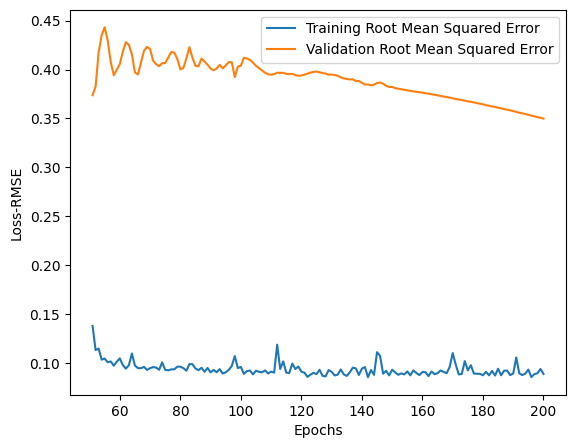

In [ ]:

# +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++


my_LSTM_model2 = myModel()

my_LSTM_model2.compile(optimizer=tf.keras.optimizers.Adam(),
                      loss='mse',    # función de costo "mse"
                      metrics=[tf.keras.metrics.RootMeanSquaredError()]   #  RMSE- despliega
                      )


H = my_LSTM_model2.fit(Train_X,
                       Train_Y,
                       epochs=200,
                       validation_data=(Test_X, Test_Y),
                       callbacks=[callback],

                       )



N = 50  # Para omitir los N primeros valores en la gráfica, que en ocasiones son
        # demasiado grandes los errores y no dejan apreciar las curvas de aprendizaje.

epochs = range(N+1, len(H.history["loss"]) + 1)

fig, ax2 = plt.subplots()
fig.set_figheight(5)
ax2.plot(epochs, H.history["root_mean_squared_error"][N:], label = "Training Root Mean Squared Error")
ax2.plot(epochs, H.history["val_root_mean_squared_error"][N:], label = "Validation Root Mean Squared Error")
ax2.set(xlabel = "Epochs", ylabel = "Loss-RMSE")
ax2.legend()

plt.show()

In [ ]:
#pred_LSTM = H.model.predict(Test_X) scaled
pred_LSTM_escalado = my_LSTM_model2.predict(Test_X).reshape(-1)
pred_LSTM_escalado.shape

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 506ms/step


(6480,)

In [ ]:
# Calculamos el error RMSE con datos escalados:

pred_LSTM_escalado = H.model.predict(Test_X)
#pred_LSTM = my_LSTM_model2.predict(Test_X).reshape(-1)

pred_LSTM_escalado = pred_LSTM_escalado.reshape(-1)[-20:]  # Select the last 20 values
rmse = np.sqrt(mean_squared_error(test_escalado['y'].values, pred_LSTM_escalado))

print('\nError-Modelo-FacebookProphet con datos escalados: RMSE: %.3f' % rmse)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step

Error-Modelo-FacebookProphet con datos escalados: RMSE: 0.504


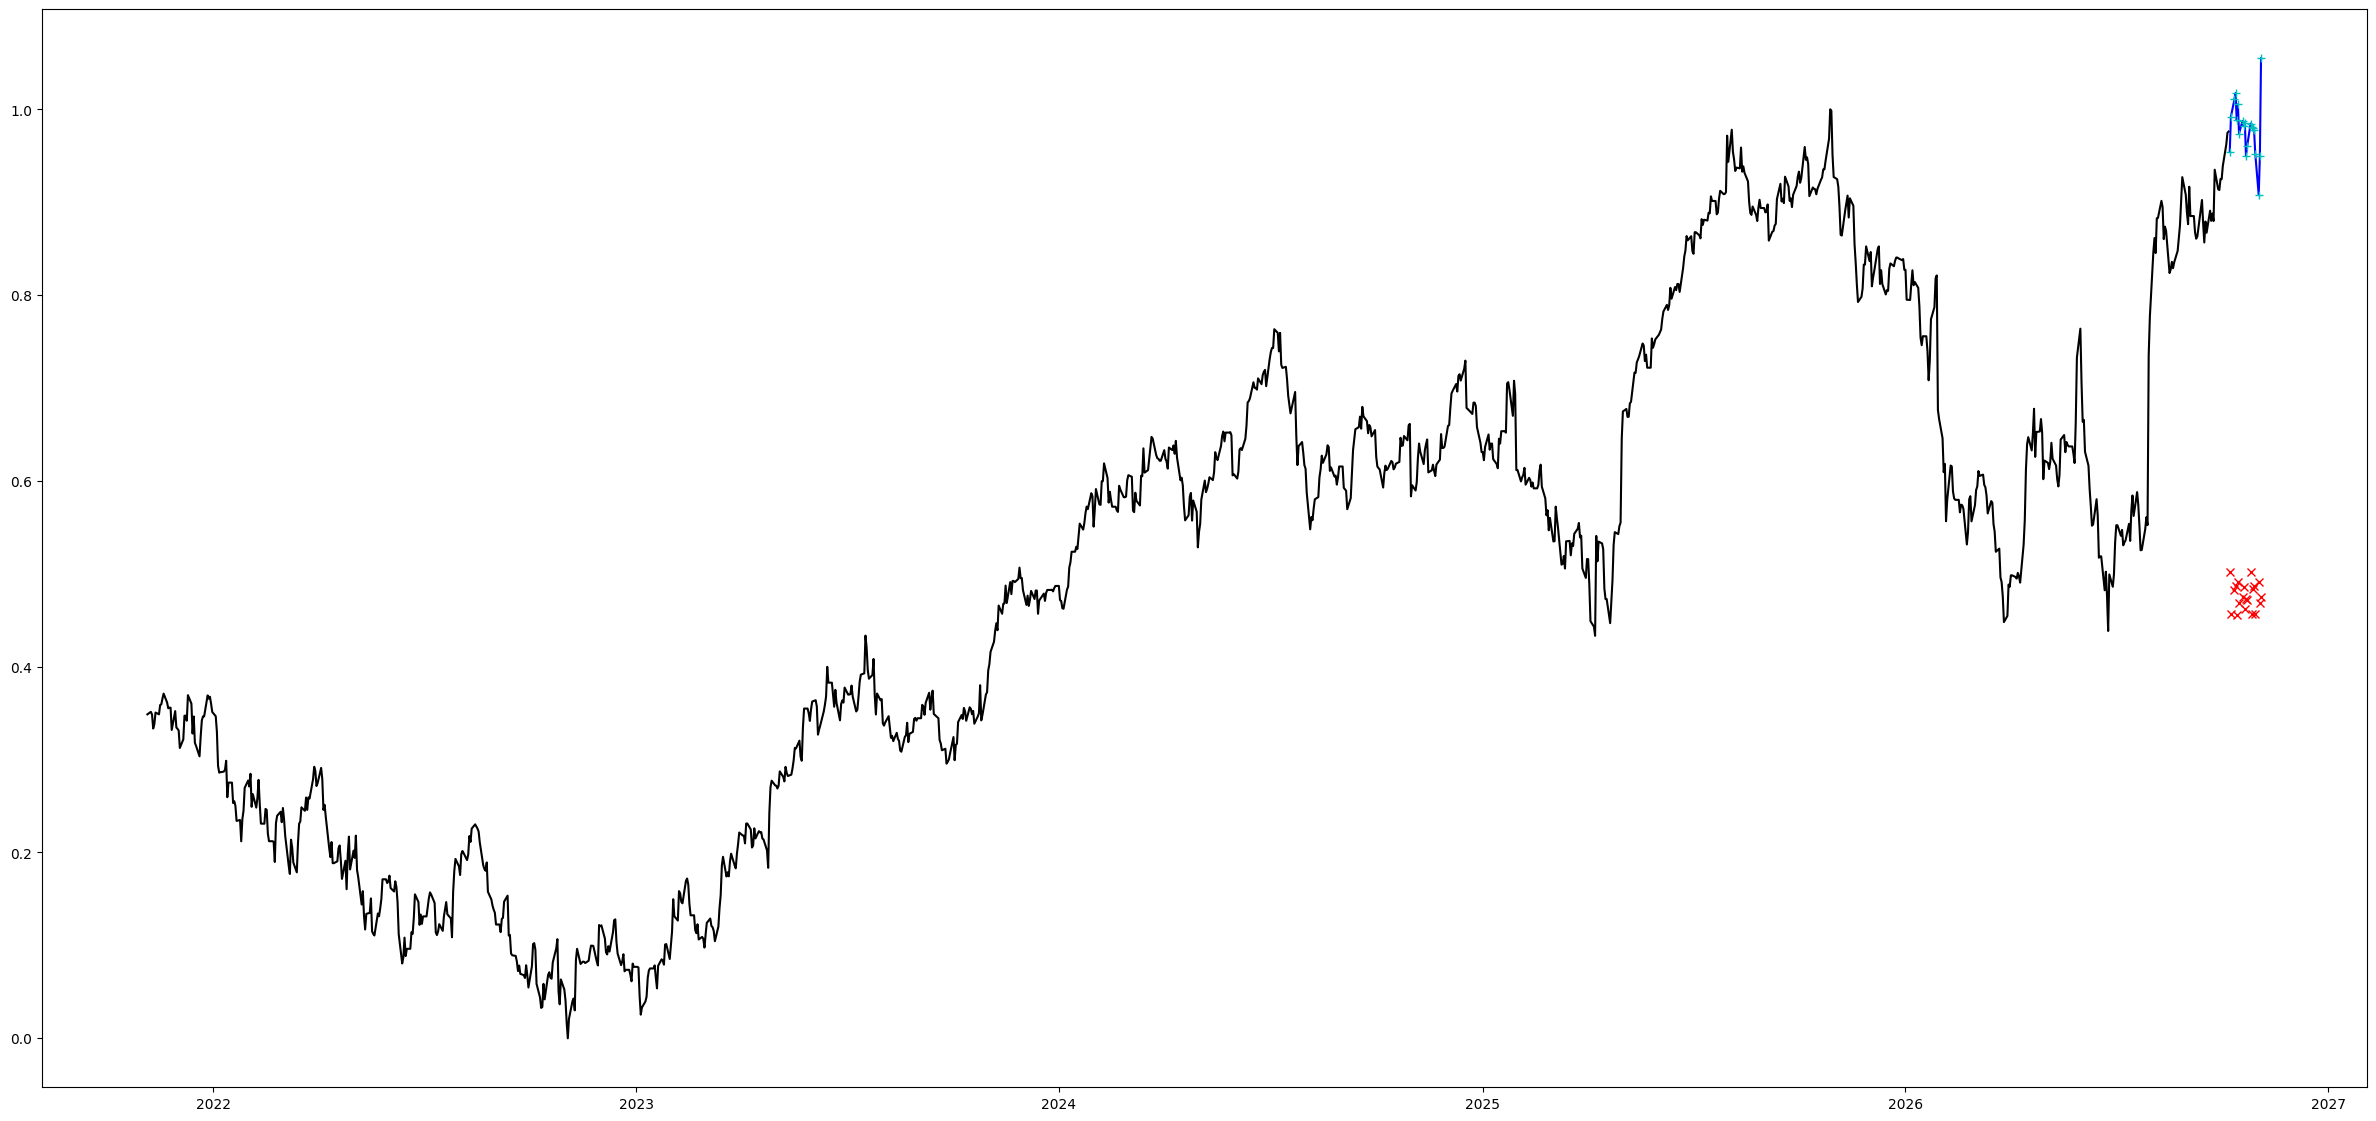

In [ ]:
# Graficamos los resultados:
fig, ax = plt.subplots(figsize=(30, 14))
ax = plt.plot(train_escalado['ds'], train_escalado['y'], '-k')  # Datos de entrenamiento de 1949 a 1959.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '-b')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], test_escalado['y'], '+c')    # Datos de prueba del año 1960.
ax = plt.plot(test_escalado['ds'], pred_LSTM_escalado, 'xr')

#<FONT COLOR=ORANGE>**Interpretación Gráfica. Comparativa con lo obtenido en Datos Originales**

-----------------------------------------------------------------------------

Igual que con los datos originales, las predicciones del LSTM forman una nube casi horizontal alrededor de 0.47, muy por debajo de los valores reales, que estuvieron entre 0.9 y 1.05. El RMSE fue de **0.504**, equivalente a unos 166 dólares, es decir, peor que el resultado con datos originales (74.123).

En esta versión se cambió la configuración de la red (más neuronas, más Dropout y otro calendario de aprendizaje), por lo que no se puede atribuir el resultado únicamente al escalamiento. Lo que sí se observa es que, con esta configuración, escalar los datos no mejoró al modelo.

-----------------------------------------------------------------------------

# **CONCLUSIÓN DE LA ACTIVIDAD**


-----------------------------------------------------------------------------
# **¿Consideras que el escalamiento de los datos ayude a obtener mejores predicciones? Justifica tu respuesta.**

En este caso, **no**. El escalamiento no mejoró las predicciones de ninguno de los modelos; solo cambió la escala en que se expresa el error. A continuación se explica por modelo:

### **Modelo Ingenuo**

No hay ninguna mejora. Este modelo solo repite el valor del día anterior, por lo que sus predicciones son las mismas con o sin escalamiento. El error de 11.000 dólares y el de 0.033 son el mismo error expresado en unidades distintas.

### **Modelo ARIMA**

Tampoco hay una mejora real. ARIMA trabaja con las diferencias entre valores consecutivos, por lo que no depende de qué tan grandes sean los números. La pequeña diferencia entre 10.794 (original) y 0.039 (escalado, equivalente a unos 13 dólares) se debe a que se usó una configuración distinta, no al escalamiento.

### **Modelo Facebook-Meta-Prophet**

No cambia de forma importante. Prophet ya maneja por sí mismo valores de cualquier tamaño, y su error escalado (0.047, unos 15 dólares) es casi igual al original (14.278).

### **Modelo Long Short Term Memory (LSTM)**

Es el único modelo en el que el escalamiento suele recomendarse, porque las redes neuronales aprenden mejor con valores pequeños. Sin embargo, aquí el resultado no mejoró: el error pasó de 74.123 a 0.504 (unos 166 dólares). Como en la versión escalada también se cambió la configuración de la red, no es posible atribuirlo solo al escalamiento, pero sí queda claro que el modelo necesita más ajustes.

A continación se muestra una tabla comparativa con los valores RMSE de datos originales y datos escalados de cada uno de los modelos:


| # | Modelo  | Datos Originales RMSE | Datos Escalados RMSE |
|---|---------|-----------------------|----------------------|
| 1 | Modelo Ingenuo (Baseline / Persistance / Naive model) | 11.000 | 0.033 |
| 2 | Modelo ARIMA | 10.794 | 0.039 |
| 3 | Modelo Facebook-Meta-Prophet | 14.278 | 0.047 |
| 4 | Long Short Term Memory (LSTM) | 74.123 | 0.504 |

------------------------------------------------------------------------
# **INTERPRETACION de resultados RMSE**


### **RMSE DATOS ORIGINALES**

Con los datos originales el error está en dólares. ARIMA (10.794) y el modelo ingenuo (11.000) quedaron prácticamente empatados, Prophet se equivocó unos 3 dólares más (14.278) y el LSTM tuvo un error mucho mayor (74.123), cerca de siete veces el del modelo ingenuo.


++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

### **RMSE DATOS ESCALADOS**

Con los datos escalados el error se expresa en una escala de 0 a 1, por lo que sus valores no se pueden comparar directamente con los originales. Para tener una idea, se puede multiplicar por el rango de precios del entrenamiento (unos 330 dólares): el modelo ingenuo equivale a unos 11 dólares, ARIMA a unos 13, Prophet a unos 15 y el LSTM a unos 166. El orden de los modelos es el mismo que con los datos originales, salvo que aquí el modelo ingenuo quedó ligeramente por encima de ARIMA.


+++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

# **En conclusión:**

Para predecir el precio de cierre ajustado de Microsoft en los siguientes 20 días, los modelos más sencillos (el ingenuo y ARIMA) fueron los que mejor funcionaron, con un error cercano a los 11 dólares, alrededor del 2 % del precio de la acción. Prophet fue algo menos preciso y el LSTM fue el que peor resultado dio.

Escalar los datos no mejoró las predicciones: solo cambió las unidades del error, y el orden de los modelos se mantuvo casi igual. Esto se debe a que el precio de un día depende sobre todo del precio del día anterior, por lo que un modelo más complejo no necesariamente da mejores resultados. También es importante recordar que ningún modelo logró anticipar el salto del último día, así que estos pronósticos sirven como una referencia a corto plazo y no como una garantía de lo que hará el mercado.

------------------------------------------------------------------------

# **Referencias Bibliográficas**

Norton, V. (2011). Adjusted closing prices. arXiv preprint arXiv:1105.2956.

Luo, Y. X., & Ji, Y. (2022, September). Prediction of the Stock Adjusted Closing Price Based On Improved PSO-LSTM Neural Network. In 2022 International Conference on Machine Learning and Cybernetics (ICMLC) (pp. 43-48). IEEE.

Wijaya, A. C., Kusumaningrum, R., Sugiharto, A., & Aryotejo, G. (2024, July). Prophet Algorithm Optimization with Particle Swarm Optimization for Adjusted Closing Price Forecasting in Xiaomi Corporation. In 2024 7th International Conference on Informatics and Computational Sciences (ICICoS) (pp. 376-381). IEEE.


----------------------------------------------------------------------------

>> ## **Fin del Ejercicio de Series de Tiempo**